In [2]:
import torch

if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

print(device)

cpu


In [3]:

import os
import json
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from shapely import wkt
from tqdm.auto import tqdm

print("Environment ready!")

Environment ready!


In [4]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/T229')

folders = [
    'data',
    'notebooks',
    'outputs',
    'checkpoints',
    'reports'
]

for folder in folders:
  (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print('Project Folders Created!')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project Folders Created!


## Downloading the data


In [5]:

# import os
# import subprocess

# save_path = "/content/drive/MyDrive/T229/data/train_images_labels_targets.tar.gz"
# os.makedirs(os.path.dirname(save_path), exist_ok=True)

# url = input("Paste the fresh xView2 download URL here: ").strip()

# print("Starting dataset download...")
# result = subprocess.run([
#     "curl", "-L", "--fail",
#     "--retry", "5",
#     "--retry-all-errors",
#     "-C", "-",
#     "-o", save_path,
#     url
# ])

# if result.returncode == 0:
#     size_gb = os.path.getsize(save_path) / (1024**3)
#     print(f"\nDownload completed! File size: {size_gb:.2f} GB")
# else:
#     print("\nDownload did not complete. Check the error above.")

In [6]:

# import os
# import tarfile

# path = "/content/drive/MyDrive/T229/data/train_images_labels_targets.tar.gz"

# print("File exists:", os.path.exists(path))
# print("File size (GB):", round(os.path.getsize(path) / (1024**3), 2))

# print("\nChecking archive integrity...")
# try:
#     with tarfile.open(path, "r:gz") as archive:
#         print("Archive opened successfully!")
#         print("Number of entries:", len(archive.getmembers()))
#         print("\nFirst 10 entries:")
#         for member in archive.getmembers()[:10]:
#             print(member.name)
# except Exception as e:
#     print("Archive verification failed:", repr(e))

In [7]:

# import os
# import tarfile

# archive_path = "/content/drive/MyDrive/T229/data/train_images_labels_targets.tar.gz"
# extract_path = "/content/drive/MyDrive/T229/data"

# print("Extracting dataset... Please wait.")

# with tarfile.open(archive_path, "r:gz") as archive:
#     archive.extractall(path=extract_path, filter="data")

# print("\nExtraction completed!")

# train_path = os.path.join(extract_path, "train")
# print("Training folder exists:", os.path.isdir(train_path))
# print("Training subfolders:", os.listdir(train_path))

##

In [8]:

import os
import json
from collections import Counter

base = "/content/drive/MyDrive/T229/data/train"

for folder in ["images", "labels", "targets"]:
    path = os.path.join(base, folder)
    files = os.listdir(path)
    print(f"{folder}: {len(files)} entries")
    print("  Examples:", files[:5])

print("\n--- Inspecting one JSON annotation ---")

labels_dir = os.path.join(base, "labels")
json_files = [
    f for f in os.listdir(labels_dir)
    if f.endswith(".json")
]

if json_files:
    sample_path = os.path.join(labels_dir, json_files[0])

    with open(sample_path, "r") as f:
        sample = json.load(f)

    print("Sample file:", json_files[0])
    print("Top-level keys:", list(sample.keys()))
    print(json.dumps(sample, indent=2)[:3000])
else:
    print("No JSON annotation files found.")

images: 5598 entries
  Examples: ['socal-fire_00000577_pre_disaster.png', 'socal-fire_00000549_pre_disaster.png', 'socal-fire_00000581_pre_disaster.png', 'socal-fire_00000573_post_disaster.png', 'socal-fire_00000572_post_disaster.png']
labels: 5598 entries
  Examples: ['socal-fire_00000457_pre_disaster.json', 'socal-fire_00000471_pre_disaster.json', 'socal-fire_00000522_post_disaster.json', 'socal-fire_00000497_post_disaster.json', 'socal-fire_00000500_pre_disaster.json']
targets: 5598 entries
  Examples: ['hurricane-harvey_00000400_post_disaster_target.png', 'mexico-earthquake_00000020_pre_disaster_target.png', 'santa-rosa-wildfire_00000155_post_disaster_target.png', 'hurricane-harvey_00000266_post_disaster_target.png', 'socal-fire_00000389_post_disaster_target.png']

--- Inspecting one JSON annotation ---
Sample file: socal-fire_00000457_pre_disaster.json
Top-level keys: ['features', 'metadata']
{
  "features": {
    "lng_lat": [],
    "xy": []
  },
  "metadata": {
    "sensor": "WOR

In [9]:

import os
import json
from PIL import Image

base = "/content/drive/MyDrive/T229/data/train"

# Inspect one image
image_name = "hurricane-michael_00000239_post_disaster.png"
image_path = os.path.join(base, "images", image_name)

with Image.open(image_path) as img:
    print("Image:", image_name)
    print("Image dimensions:", img.size)
    print("Image mode:", img.mode)

# Inspect matching annotation
label_name = image_name.replace(".png", ".json")
label_path = os.path.join(base, "labels", label_name)

print("\nMatching label exists:", os.path.exists(label_path))

if os.path.exists(label_path):
    with open(label_path, "r") as f:
        annotation = json.load(f)

    print("Metadata:")
    print(json.dumps(annotation.get("metadata", {}), indent=2))

    features = annotation.get("features", {})
    polygons = features.get("lng_lat", [])
    print("\nNumber of building annotations:", len(polygons))

    from collections import Counter
    counts = Counter(
        item.get("properties", {}).get("subtype", "unknown")
        for item in polygons
        if item.get("properties", {}).get("feature_type") == "building"
    )
    print("Damage categories:", dict(counts))

Image: hurricane-michael_00000239_post_disaster.png
Image dimensions: (1024, 1024)
Image mode: RGB

Matching label exists: True
Metadata:
{
  "sensor": "GEOEYE01",
  "provider_asset_type": "GEOEYE01",
  "gsd": 2.0711906,
  "capture_date": "2018-10-13T16:48:15.000Z",
  "off_nadir_angle": 28.86673,
  "pan_resolution": 0.5171161,
  "sun_azimuth": 163.92638,
  "sun_elevation": 50.756794,
  "target_azimuth": 112.555626,
  "disaster": "hurricane-michael",
  "disaster_type": "wind",
  "catalog_id": "105001001292E000",
  "original_width": 1024,
  "original_height": 1024,
  "width": 1024,
  "height": 1024,
  "id": "MjU0NjI4MQ.7blCGLCK-n1pdBcqikQ3-5T2Iqs",
  "img_name": "hurricane-michael_00000239_post_disaster.png"
}

Number of building annotations: 146
Damage categories: {'no-damage': 79, 'minor-damage': 28, 'major-damage': 23, 'destroyed': 15, 'un-classified': 1}


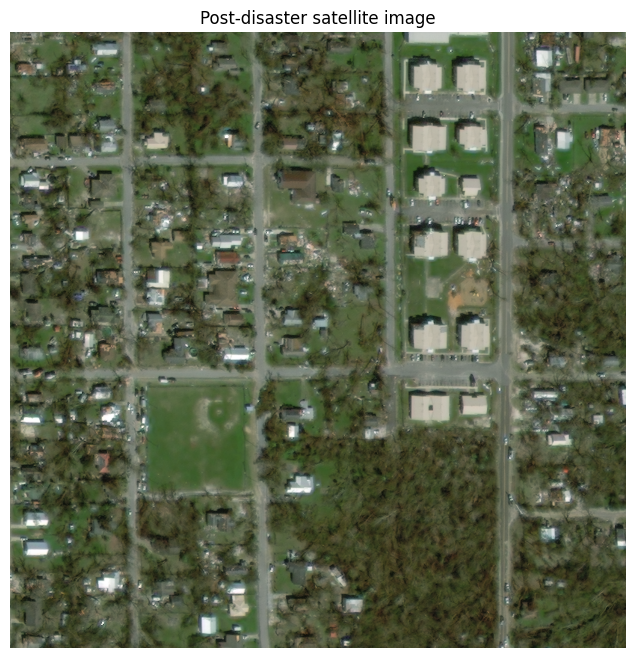

Image loaded successfully.
Image size: (1024, 1024)
Building annotations: 146


In [10]:

import os
import json
import matplotlib.pyplot as plt
from PIL import Image

base = "/content/drive/MyDrive/T229/data/train"

image_name = "hurricane-michael_00000239_post_disaster.png"
image_path = os.path.join(base, "images", image_name)

with Image.open(image_path) as img:
    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.title("Post-disaster satellite image")
    plt.axis("off")
    plt.show()

label_path = os.path.join(
    base, "labels",
    image_name.replace(".png", ".json")
)

with open(label_path, "r") as f:
    annotation = json.load(f)

print("Image loaded successfully.")
print("Image size:", Image.open(image_path).size)
print("Building annotations:", len(annotation["features"]["lng_lat"]))

In [11]:

import os
import json

base = "/content/drive/MyDrive/T229/data/train"
image_name = "hurricane-michael_00000239_post_disaster.png"
label_path = os.path.join(
    base, "labels", image_name.replace(".png", ".json")
)

with open(label_path, "r") as f:
    annotation = json.load(f)

print("Metadata keys:")
print(list(annotation["metadata"].keys()))

print("\nFeature groups:")
for key, value in annotation["features"].items():
    print(key, ":", len(value) if isinstance(value, list) else type(value).__name__)

print("\nFirst building properties:")
print(json.dumps(
    annotation["features"]["lng_lat"][0]["properties"],
    indent=2
))

Metadata keys:
['sensor', 'provider_asset_type', 'gsd', 'capture_date', 'off_nadir_angle', 'pan_resolution', 'sun_azimuth', 'sun_elevation', 'target_azimuth', 'disaster', 'disaster_type', 'catalog_id', 'original_width', 'original_height', 'width', 'height', 'id', 'img_name']

Feature groups:
lng_lat : 146
xy : 146

First building properties:
{
  "feature_type": "building",
  "subtype": "no-damage",
  "uid": "3166a980-01b9-48f9-b495-671fa153ba67"
}


In [12]:

# Inspect the first building annotation in pixel coordinates

first_building = annotation["features"]["xy"][0]

print("Building properties:")
print(json.dumps(first_building["properties"], indent=2))

print("\nPolygon coordinates:")
print(first_building["wkt"])

Building properties:
{
  "feature_type": "building",
  "subtype": "no-damage",
  "uid": "3166a980-01b9-48f9-b495-671fa153ba67"
}

Polygon coordinates:
POLYGON ((971.0000001361618 0.00233923960989422, 971.0000001371612 11.00000005043828, 954.0000001358339 11.00000005243724, 954.000000137583 0.002664089717760834, 971.0000001361618 0.00233923960989422))


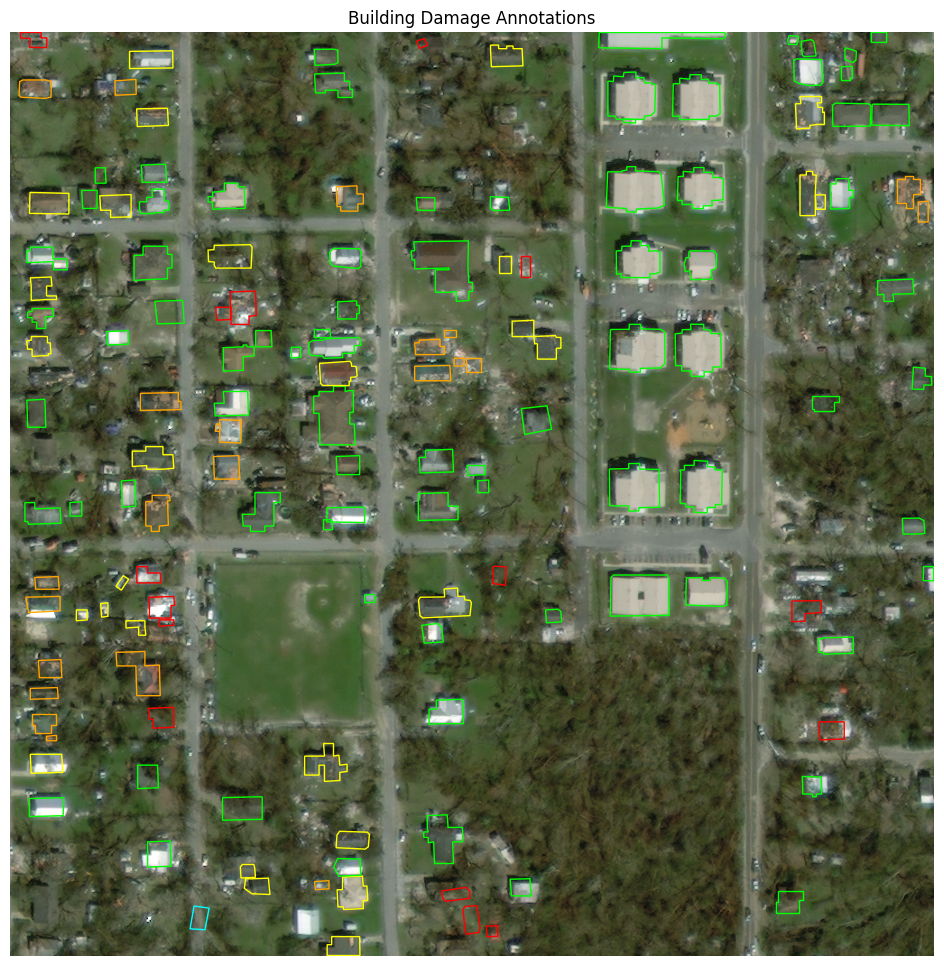

In [13]:

import matplotlib.pyplot as plt
from PIL import Image
from shapely import wkt
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
import os

# Load the image
image_path = os.path.join(
    base, "images", image_name
)
img = Image.open(image_path).convert("RGB")

# Damage category colors
damage_colors = {
    "no-damage": "lime",
    "minor-damage": "yellow",
    "major-damage": "orange",
    "destroyed": "red",
    "un-classified": "cyan"
}

fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(img)

for feature in annotation["features"]["xy"]:
    props = feature["properties"]
    polygon = wkt.loads(feature["wkt"])

    if polygon.geom_type != "Polygon":
        continue

    coords = list(polygon.exterior.coords)
    patch = MplPolygon(
        coords,
        closed=True,
        fill=False,
        edgecolor=damage_colors.get(
            props.get("subtype"), "white"
        ),
        linewidth=1
    )
    ax.add_patch(patch)

ax.set_title("Building Damage Annotations")
ax.axis("off")
plt.show()

In [14]:

from collections import Counter
import json
import os

labels_dir = os.path.join(base, "labels")

damage_counts = Counter()
total_buildings = 0
files_checked = 0

for filename in os.listdir(labels_dir):
    if not filename.endswith(".json"):
        continue

    path = os.path.join(labels_dir, filename)

    with open(path, "r") as f:
        data = json.load(f)

    buildings = data["features"]["xy"]

    for building in buildings:
        subtype = building["properties"].get(
            "subtype", "un-classified"
        )
        damage_counts[subtype] += 1
        total_buildings += 1

    files_checked += 1

print("Label files checked:", files_checked)
print("Total building annotations:", total_buildings)
print("\nDamage class distribution:")

for label, count in damage_counts.most_common():
    percentage = count / total_buildings * 100
    print(f"{label:15s}: {count:8,d} ({percentage:.2f}%)")

Label files checked: 5598
Total building annotations: 325574

Damage class distribution:
un-classified  :  165,780 (50.92%)
no-damage      :  117,426 (36.07%)
minor-damage   :   14,980 (4.60%)
major-damage   :   14,161 (4.35%)
destroyed      :   13,227 (4.06%)


In [15]:

import os
from collections import Counter

images_dir = os.path.join(base, "images")
image_files = [
    f for f in os.listdir(images_dir)
    if f.endswith(".png")
]

print("Total images:", len(image_files))

image_types = Counter()
disasters = Counter()

for filename in image_files:
    if "_pre_disaster" in filename:
        image_types["pre-disaster"] += 1
    elif "_post_disaster" in filename:
        image_types["post-disaster"] += 1
    else:
        image_types["other"] += 1

    disaster_name = filename.split("_")[0]
    disasters[disaster_name] += 1

print("\nImage types:")
for name, count in image_types.items():
    print(f"{name}: {count:,}")

print("\nImages per disaster (first 15):")
for name, count in disasters.most_common(15):
    print(f"{name}: {count:,}")

Total images: 5598

Image types:
pre-disaster: 2,799
post-disaster: 2,799

Images per disaster (first 15):
socal-fire: 1,646
hurricane-michael: 686
hurricane-florence: 638
hurricane-harvey: 638
midwest-flooding: 558
hurricane-matthew: 476
santa-rosa-wildfire: 452
mexico-earthquake: 242
palu-tsunami: 226
guatemala-volcano: 36


In [16]:

import os

images_dir = os.path.join(base, "images")

image_files = {
    f for f in os.listdir(images_dir)
    if f.endswith(".png")
}

pre_images = {
    f for f in image_files
    if "_pre_disaster.png" in f
}

post_images = {
    f for f in image_files
    if "_post_disaster.png" in f
}

# Remove the pre/post suffix to compare scene identifiers
pre_ids = {
    f.replace("_pre_disaster.png", "")
    for f in pre_images
}

post_ids = {
    f.replace("_post_disaster.png", "")
    for f in post_images
}

matched_ids = pre_ids & post_ids

print("Pre-disaster images:", len(pre_images))
print("Post-disaster images:", len(post_images))
print("Matched scene IDs:", len(matched_ids))
print("Pre images without a match:", len(pre_ids - post_ids))
print("Post images without a match:", len(post_ids - pre_ids))

print("\nExample matched IDs:")
for scene_id in sorted(matched_ids)[:5]:
    print(scene_id)

Pre-disaster images: 2799
Post-disaster images: 2799
Matched scene IDs: 2799
Pre images without a match: 0
Post images without a match: 0

Example matched IDs:
guatemala-volcano_00000000
guatemala-volcano_00000001
guatemala-volcano_00000002
guatemala-volcano_00000006
guatemala-volcano_00000007


In [17]:

import os
import json
import pandas as pd

images_dir = os.path.join(base, "images")
labels_dir = os.path.join(base, "labels")

rows = []
missing_labels = []

for scene_id in sorted(post_ids):
    post_name = scene_id + "_post_disaster.png"
    pre_name = scene_id + "_pre_disaster.png"
    label_name = scene_id + "_post_disaster.json"

    post_path = os.path.join(images_dir, post_name)
    pre_path = os.path.join(images_dir, pre_name)
    label_path = os.path.join(labels_dir, label_name)

    if not os.path.exists(label_path):
        missing_labels.append(label_name)
        continue

    with open(label_path, "r") as f:
        label_data = json.load(f)

    rows.append({
        "scene_id": scene_id,
        "pre_image": pre_path,
        "post_image": post_path,
        "label_json": label_path,
        "building_count": len(label_data["features"]["xy"])
    })

manifest = pd.DataFrame(rows)

manifest_path = os.path.join(
    "/content/drive/MyDrive/T229",
    "reports",
    "training_manifest.csv"
)

manifest.to_csv(manifest_path, index=False)

print("Manifest rows:", len(manifest))
print("Missing label files:", len(missing_labels))
print("Total annotated buildings:", manifest["building_count"].sum())
print("Saved to:", manifest_path)

display(manifest.head())

Manifest rows: 2799
Missing label files: 0
Total annotated buildings: 162787
Saved to: /content/drive/MyDrive/T229/reports/training_manifest.csv


,scene_id,pre_image,post_image,label_json,building_count
0,guatemala-volcano_00000000,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/labels/...,10
1,guatemala-volcano_00000001,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/labels/...,4
2,guatemala-volcano_00000002,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/labels/...,1
3,guatemala-volcano_00000006,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/labels/...,97
4,guatemala-volcano_00000007,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/labels/...,9


In [18]:

import json
from collections import Counter
from shapely import wkt

damage_counts = Counter()
invalid_polygons = 0
total_buildings = 0

for label_path in manifest["label_json"]:
    with open(label_path, "r") as f:
        data = json.load(f)

    for feature in data["features"]["xy"]:
        total_buildings += 1
        subtype = feature["properties"].get(
            "subtype", "un-classified"
        )

        if subtype == "un-classified":
            continue

        try:
            polygon = wkt.loads(feature["wkt"])
            min_x, min_y, max_x, max_y = polygon.bounds

            if (
                polygon.is_empty
                or not polygon.is_valid
                or min_x < 0 or min_y < 0
                or max_x > 1024 or max_y > 1024
            ):
                invalid_polygons += 1
                continue

            damage_counts[subtype] += 1

        except Exception:
            invalid_polygons += 1

print("Total post-disaster annotations:", total_buildings)
print("Valid classified building polygons:")
for label, count in damage_counts.most_common():
    print(f"{label:15s}: {count:,}")

print("Invalid/out-of-bounds classified polygons:", invalid_polygons)
print("Total usable classified buildings:", sum(damage_counts.values()))

Total post-disaster annotations: 162787
Valid classified building polygons:
no-damage      : 115,602
minor-damage   : 14,895
major-damage   : 13,811
destroyed      : 13,057
Invalid/out-of-bounds classified polygons: 2429
Total usable classified buildings: 157365


In [19]:

import json
import random
import pandas as pd
from shapely import wkt

random.seed(42)

damage_classes = [
    "no-damage",
    "minor-damage",
    "major-damage",
    "destroyed"
]

max_per_class = 3000
samples_by_class = {label: [] for label in damage_classes}

for _, row in manifest.iterrows():
    with open(row["label_json"], "r") as f:
        data = json.load(f)

    for feature in data["features"]["xy"]:
        props = feature["properties"]
        label = props.get("subtype", "un-classified")

        if label not in damage_classes:
            continue

        try:
            polygon = wkt.loads(feature["wkt"])
            min_x, min_y, max_x, max_y = polygon.bounds

            if (
                polygon.is_empty
                or not polygon.is_valid
                or min_x < 0 or min_y < 0
                or max_x > 1024 or max_y > 1024
            ):
                continue

            if len(samples_by_class[label]) < max_per_class:
                samples_by_class[label].append({
                    "scene_id": row["scene_id"],
                    "image_path": row["post_image"],
                    "label": label,
                    "polygon_wkt": feature["wkt"]
                })

        except Exception:
            continue

samples = []
for label in damage_classes:
    samples.extend(samples_by_class[label])

random.shuffle(samples)
sample_df = pd.DataFrame(samples)

sample_path = (
    "/content/drive/MyDrive/T229/reports/"
    "balanced_building_sample.csv"
)
sample_df.to_csv(sample_path, index=False)

print("Sample count:", len(sample_df))
print("\nSamples per class:")
print(sample_df["label"].value_counts())
print("\nSaved to:", sample_path)

Sample count: 12000

Samples per class:
label
minor-damage    3000
major-damage    3000
no-damage       3000
destroyed       3000
Name: count, dtype: int64

Saved to: /content/drive/MyDrive/T229/reports/balanced_building_sample.csv


In [20]:

import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

sample_path = (
    "/content/drive/MyDrive/T229/reports/"
    "balanced_building_sample.csv"
)

sample_df = pd.read_csv(sample_path)

# Split by scene so buildings from one image
# cannot appear in both sets.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        sample_df,
        groups=sample_df["scene_id"]
    )
)

train_df = sample_df.iloc[train_idx].copy()
val_df = sample_df.iloc[val_idx].copy()

print("Training examples:", len(train_df))
print("Validation examples:", len(val_df))

print(
    "Scenes shared between sets:",
    len(set(train_df["scene_id"]) & set(val_df["scene_id"]))
)

print("\nTraining class distribution:")
print(train_df["label"].value_counts())

print("\nValidation class distribution:")
print(val_df["label"].value_counts())

output_dir = "/content/drive/MyDrive/T229/reports"

train_df.to_csv(
    f"{output_dir}/train_buildings.csv", index=False
)
val_df.to_csv(
    f"{output_dir}/val_buildings.csv", index=False
)

print("\nSplit files saved successfully.")

Training examples: 9114
Validation examples: 2886
Scenes shared between sets: 0

Training class distribution:
label
minor-damage    2360
no-damage       2349
destroyed       2221
major-damage    2184
Name: count, dtype: int64

Validation class distribution:
label
major-damage    816
destroyed       779
no-damage       651
minor-damage    640
Name: count, dtype: int64

Split files saved successfully.


In [21]:

import os
import pandas as pd
from PIL import Image
from shapely import wkt

train_df = pd.read_csv(
    "/content/drive/MyDrive/T229/reports/train_buildings.csv"
)

# Use a small pilot batch first
pilot_df = train_df.head(20).copy()

crop_root = "/content/drive/MyDrive/T229/data/building_crops_pilot"
os.makedirs(crop_root, exist_ok=True)

for label in [
    "no-damage", "minor-damage",
    "major-damage", "destroyed"
]:
    os.makedirs(os.path.join(crop_root, label), exist_ok=True)

for idx, row in pilot_df.iterrows():
    image = Image.open(row["image_path"]).convert("RGB")
    polygon = wkt.loads(row["polygon_wkt"])
    min_x, min_y, max_x, max_y = polygon.bounds

    # Add context around each building
    pad = 16
    left = max(0, int(min_x) - pad)
    top = max(0, int(min_y) - pad)
    right = min(image.width, int(max_x) + pad + 1)
    bottom = min(image.height, int(max_y) + pad + 1)

    # Skip degenerate crops
    if right <= left or bottom <= top:
        continue

    crop = image.crop((left, top, right, bottom))
    crop = crop.resize((128, 128), Image.Resampling.BILINEAR)

    filename = f"{idx}_{row['scene_id']}.png"
    save_path = os.path.join(
        crop_root, row["label"], filename
    )
    crop.save(save_path)

print("Pilot crops created:", len(pilot_df))
print("Crop directory:", crop_root)

Pilot crops created: 20
Crop directory: /content/drive/MyDrive/T229/data/building_crops_pilot


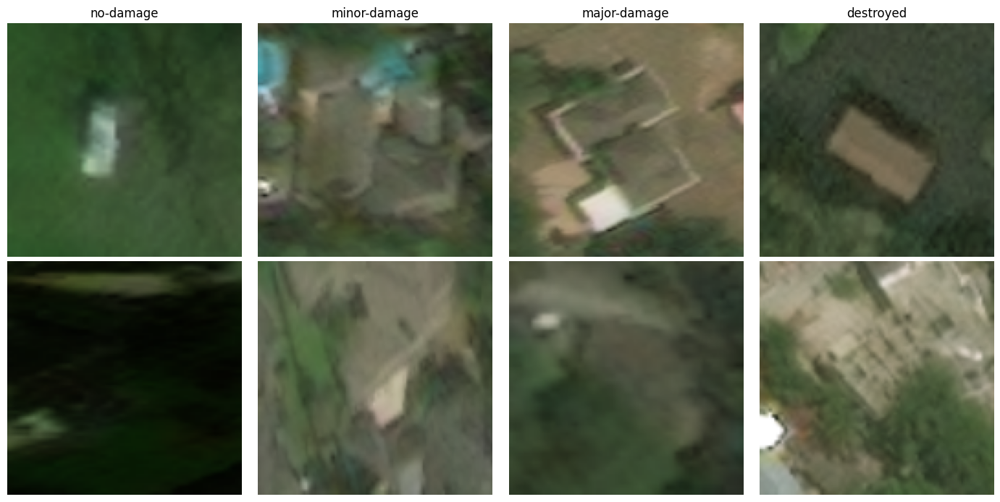

In [22]:

import matplotlib.pyplot as plt
from PIL import Image
import os

labels = [
    "no-damage",
    "minor-damage",
    "major-damage",
    "destroyed"
]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for col, label in enumerate(labels):
    folder = os.path.join(crop_root, label)
    filenames = sorted(os.listdir(folder))[:2]

    for row_idx in range(2):
        ax = axes[row_idx, col]

        if row_idx < len(filenames):
            img = Image.open(
                os.path.join(folder, filenames[row_idx])
            )
            ax.imshow(img)
            ax.set_title(label if row_idx == 0 else "")
        else:
            ax.set_visible(False)

        ax.axis("off")

plt.tight_layout()
plt.show()

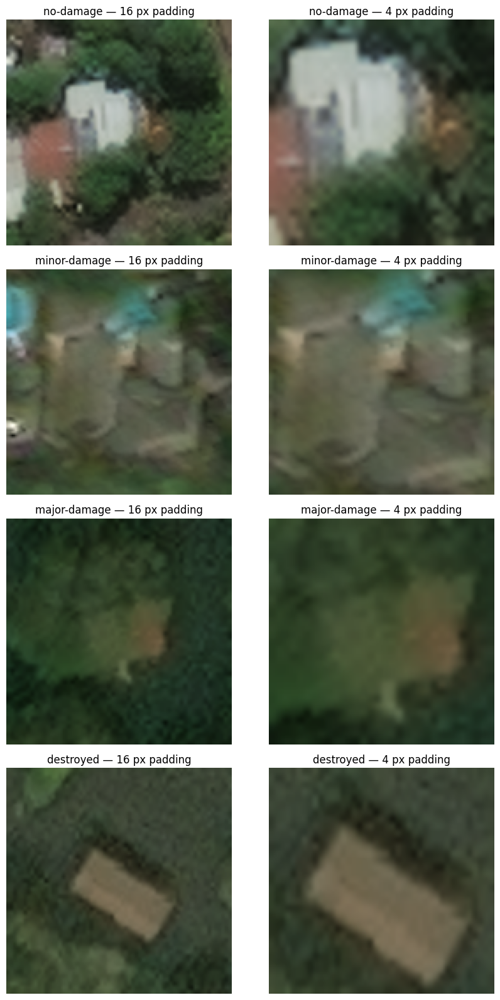

In [23]:

import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from shapely import wkt

train_df = pd.read_csv(
    "/content/drive/MyDrive/T229/reports/train_buildings.csv"
)

# Choose a few examples from different classes
examples = []
for label in [
    "no-damage", "minor-damage",
    "major-damage", "destroyed"
]:
    example = train_df[train_df["label"] == label].iloc[0]
    examples.append(example)

fig, axes = plt.subplots(4, 2, figsize=(9, 16))

for i, row in enumerate(examples):
    image = Image.open(row["image_path"]).convert("RGB")
    polygon = wkt.loads(row["polygon_wkt"])
    min_x, min_y, max_x, max_y = polygon.bounds

    # Current crop: 16-pixel padding
    current_box = (
        max(0, int(min_x) - 16),
        max(0, int(min_y) - 16),
        min(image.width, int(max_x) + 17),
        min(image.height, int(max_y) + 17)
    )

    # Tighter crop: 4-pixel padding
    tight_box = (
        max(0, int(min_x) - 4),
        max(0, int(min_y) - 4),
        min(image.width, int(max_x) + 5),
        min(image.height, int(max_y) + 5)
    )

    current_crop = image.crop(current_box).resize((128, 128))
    tight_crop = image.crop(tight_box).resize((128, 128))

    axes[i, 0].imshow(current_crop)
    axes[i, 0].set_title(f"{row['label']} — 16 px padding")
    axes[i, 1].imshow(tight_crop)
    axes[i, 1].set_title(f"{row['label']} — 4 px padding")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [24]:

import pandas as pd
import numpy as np
from shapely import wkt

sample_df = pd.read_csv(
    "/content/drive/MyDrive/T229/reports/"
    "balanced_building_sample.csv"
)

widths = []
heights = []
areas = []

for polygon_wkt in sample_df["polygon_wkt"]:
    polygon = wkt.loads(polygon_wkt)
    min_x, min_y, max_x, max_y = polygon.bounds

    widths.append(max_x - min_x)
    heights.append(max_y - min_y)
    areas.append(polygon.area)

sizes = pd.DataFrame({
    "width_px": widths,
    "height_px": heights,
    "area_px": areas
})

print("Building bounding-box dimensions:")
print(sizes[["width_px", "height_px"]].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90]
).round(2))

print("\nBuildings smaller than 8 px in either dimension:",
      ((sizes["width_px"] < 8) |
       (sizes["height_px"] < 8)).sum())

print("Buildings at least 16 px in both dimensions:",
      ((sizes["width_px"] >= 16) &
       (sizes["height_px"] >= 16)).sum())

Building bounding-box dimensions:
       width_px  height_px
count  12000.00   12000.00
mean      35.47      34.73
std       26.28      24.04
min        1.49       3.25
25%       18.48      17.80
50%       31.35      31.57
75%       46.24      46.72
90%       58.66      57.98
max      385.99     709.01

Buildings smaller than 8 px in either dimension: 415
Buildings at least 16 px in both dimensions: 9089


In [25]:

# import pandas as pd
# from PIL import Image
# from shapely import wkt

# sample_df = pd.read_csv(
#     "/content/drive/MyDrive/T229/reports/"
#     "balanced_building_sample.csv"
# )

# crop_widths = []
# crop_heights = []
# large_crop_count = 0
# invalid_count = 0

# for _, row in sample_df.iterrows():
#     polygon = wkt.loads(row["polygon_wkt"])
#     min_x, min_y, max_x, max_y = polygon.bounds

#     with Image.open(row["image_path"]) as image:
#         left = max(0, int(min_x) - 16)
#         top = max(0, int(min_y) - 16)
#         right = min(image.width, int(max_x) + 17)
#         bottom = min(image.height, int(max_y) + 17)

#     width = right - left
#     height = bottom - top

#     if width <= 0 or height <= 0:
#         invalid_count += 1
#         continue

#     crop_widths.append(width)
#     crop_heights.append(height)

#     if width > 256 or height > 256:
#         large_crop_count += 1

# print("Valid crops:", len(crop_widths))
# print("Invalid crops:", invalid_count)
# print("Crops exceeding 256 px in either dimension:", large_crop_count)
# print("Median crop width:", round(float(pd.Series(crop_widths).median()), 2))
# print("Median crop height:", round(float(pd.Series(crop_heights).median()), 2))

In [26]:

# import os
# import pandas as pd
# from PIL import Image
# from shapely import wkt
# from tqdm.auto import tqdm

# root = "/content/drive/MyDrive/T229"
# output_root = os.path.join(root, "data", "building_crops")

# train_df = pd.read_csv(
#     os.path.join(root, "reports", "train_buildings.csv")
# )
# val_df = pd.read_csv(
#     os.path.join(root, "reports", "val_buildings.csv")
# )

# for split_name, dataframe in [
#     ("train", train_df),
#     ("val", val_df)
# ]:
#     for label in [
#         "no-damage", "minor-damage",
#         "major-damage", "destroyed"
#     ]:
#         os.makedirs(
#             os.path.join(output_root, split_name, label),
#             exist_ok=True
#         )

#     for idx, row in tqdm(
#         dataframe.iterrows(),
#         total=len(dataframe),
#         desc=f"Creating {split_name} crops"
#     ):
#         polygon = wkt.loads(row["polygon_wkt"])
#         min_x, min_y, max_x, max_y = polygon.bounds

#         with Image.open(row["image_path"]) as source:
#             image = source.convert("RGB")

#         left = max(0, int(min_x) - 16)
#         top = max(0, int(min_y) - 16)
#         right = min(image.width, int(max_x) + 17)
#         bottom = min(image.height, int(max_y) + 17)

#         if right <= left or bottom <= top:
#             continue

#         crop = image.crop((left, top, right, bottom))
#         crop = crop.resize(
#             (128, 128),
#             Image.Resampling.BILINEAR
#         )

#         filename = f"{idx}_{row['scene_id']}.jpg"
#         save_path = os.path.join(
#             output_root, split_name, row["label"], filename
#         )
#         crop.save(save_path, quality=95)

# print("\nCrop generation finished.")
# print("Dataset directory:", output_root)

In [27]:

# import os

# for split_name in ["train", "val"]:
#     print(f"\n{split_name.upper()}")

#     total = 0
#     for label in [
#         "no-damage", "minor-damage",
#         "major-damage", "destroyed"
#     ]:
#         folder = os.path.join(
#             output_root, split_name, label
#         )
#         count = sum(
#             f.lower().endswith(".jpg")
#             for f in os.listdir(folder)
#         )
#         total += count
#         print(f"{label:15s}: {count:,}")

#     print("Total:", total)


In [28]:

import torch
import torchvision
from PIL import Image

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory (GB):",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024**3),
            2
        )
    )

print("Pillow version:", Image.__version__ if hasattr(Image, "__version__") else "Installed")


PyTorch version: 2.11.0+cpu
Torchvision version: 0.26.0+cpu
GPU available: False
Pillow version: 11.3.0


In [29]:

import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

dataset_root = (
    "/content/drive/MyDrive/T229/data/building_crops"
)

# Standard normalization for ImageNet-pretrained models
image_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    os.path.join(dataset_root, "train"),
    transform=image_transform
)

val_dataset = datasets.ImageFolder(
    os.path.join(dataset_root, "val"),
    transform=image_transform
)

batch_size = 32
num_workers = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True
)

print("Class mapping:", train_dataset.class_to_idx)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

images, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)


Class mapping: {'destroyed': 0, 'major-damage': 1, 'minor-damage': 2, 'no-damage': 3}
Training images: 9114
Validation images: 2886
Training batches: 285
Validation batches: 91


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Batch image shape: torch.Size([32, 3, 128, 128])
Batch label shape: torch.Size([32])


In [30]:

import torch
import torch.nn as nn
from torchvision import models

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load ImageNet-pretrained ResNet-18
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Replace the final layer with four damage classes
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 4)

model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Device:", device)
print("Final classification layer:", model.fc)
print("Number of output classes:", model.fc.out_features)

# Test a batch through the model
images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 112MB/s]


AttributeError: partially initialized module 'torch._dynamo' from '/usr/local/lib/python3.13/dist-packages/torch/_dynamo/__init__.py' has no attribute 'decorators' (most likely due to a circular import)

In [ ]:

# import os
# import copy
# import numpy as np
# import pandas as pd
# import torch
# from sklearn.metrics import accuracy_score, f1_score
# from tqdm.auto import tqdm

# epochs = 3
# best_f1 = -1.0
# history = []

# checkpoint_dir = (
#     "/content/drive/MyDrive/T229/checkpoints"
# )
# os.makedirs(checkpoint_dir, exist_ok=True)

# best_model_path = os.path.join(
#     checkpoint_dir, "resnet18_damage_best.pth"
# )

# for epoch in range(epochs):
#     # Training
#     model.train()
#     running_loss = 0.0

#     progress = tqdm(
#         train_loader,
#         desc=f"Epoch {epoch + 1}/{epochs} - train"
#     )

#     for images, labels in progress:
#         images = images.to(device, non_blocking=True)
#         labels = labels.to(device, non_blocking=True)

#         optimizer.zero_grad(set_to_none=True)

#         outputs = model(images)
#         loss = criterion(outputs, labels)

#         loss.backward()
#         optimizer.step()

#         running_loss += loss.item() * images.size(0)
#         progress.set_postfix(loss=f"{loss.item():.4f}")

#     train_loss = running_loss / len(train_dataset)

#     # Validation
#     model.eval()
#     val_loss_sum = 0.0
#     all_labels = []
#     all_predictions = []

#     with torch.no_grad():
#         for images, labels in tqdm(
#             val_loader,
#             desc=f"Epoch {epoch + 1}/{epochs} - val"
#         ):
#             images = images.to(device, non_blocking=True)
#             labels = labels.to(device, non_blocking=True)

#             outputs = model(images)
#             loss = criterion(outputs, labels)

#             val_loss_sum += loss.item() * images.size(0)

#             predictions = outputs.argmax(dim=1)
#             all_labels.extend(labels.cpu().numpy())
#             all_predictions.extend(predictions.cpu().numpy())

#     val_loss = val_loss_sum / len(val_dataset)
#     val_accuracy = accuracy_score(
#         all_labels, all_predictions
#     )
#     val_macro_f1 = f1_score(
#         all_labels,
#         all_predictions,
#         average="macro",
#         zero_division=0
#     )

#     history.append({
#         "epoch": epoch + 1,
#         "train_loss": train_loss,
#         "val_loss": val_loss,
#         "val_accuracy": val_accuracy,
#         "val_macro_f1": val_macro_f1
#     })

#     print(f"\nEpoch {epoch + 1}/{epochs}")
#     print(f"Train loss:      {train_loss:.4f}")
#     print(f"Validation loss: {val_loss:.4f}")
#     print(f"Validation acc:  {val_accuracy:.4f}")
#     print(f"Validation F1:   {val_macro_f1:.4f}")

#     # Save the best model based on validation macro-F1
#     if val_macro_f1 > best_f1:
#         best_f1 = val_macro_f1
#         torch.save({
#             "epoch": epoch + 1,
#             "model_state_dict": model.state_dict(),
#             "optimizer_state_dict": optimizer.state_dict(),
#             "class_to_idx": train_dataset.class_to_idx,
#             "val_macro_f1": val_macro_f1
#         }, best_model_path)

#         print("Saved new best checkpoint.")

# history_df = pd.DataFrame(history)
# history_path = os.path.join(
#     "/content/drive/MyDrive/T229/reports",
#     "resnet18_training_history.csv"
# )
# history_df.to_csv(history_path, index=False)

# print("\nTraining finished.")
# print("Best validation macro-F1:", round(best_f1, 4))
# print("Best checkpoint:", best_model_path)
# print("Training history:", history_path)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Best checkpoint epoch: 1
Saved validation macro-F1: 0.8197898827208341

Classification report:
              precision    recall  f1-score   support

   destroyed     0.9462    0.8357    0.8875       779
major-damage     0.7766    0.7414    0.7586       816
minor-damage     0.6531    0.7500    0.6982       640
   no-damage     0.9123    0.9585    0.9348       651

    accuracy                         0.8177      2886
   macro avg     0.8220    0.8214    0.8198      2886
weighted avg     0.8256    0.8177    0.8198      2886



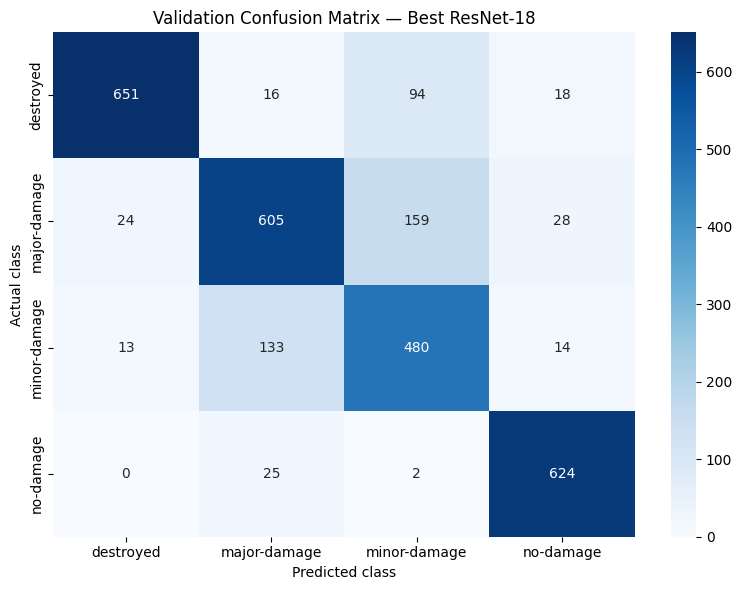

In [31]:

import os
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import models
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "resnet18_damage_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

# Restore the best model
best_model = models.resnet18(weights=None)
best_model.fc = torch.nn.Linear(
    best_model.fc.in_features, 4
)
best_model.load_state_dict(checkpoint["model_state_dict"])
best_model = best_model.to(device)
best_model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

class_names = [
    name for name, idx
    in sorted(
        val_dataset.class_to_idx.items(),
        key=lambda item: item[1]
    )
]

print("Best checkpoint epoch:", checkpoint["epoch"])
print("Saved validation macro-F1:", checkpoint["val_macro_f1"])

print("\nClassification report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Validation Confusion Matrix — Best ResNet-18")
plt.tight_layout()
plt.show()


In [32]:

# Inspect major-damage buildings predicted as minor-damage

import numpy as np

major_idx = val_dataset.class_to_idx["major-damage"]
minor_idx = val_dataset.class_to_idx["minor-damage"]

wrong_indices = [
    i for i, (actual, predicted) in enumerate(
        zip(all_labels, all_predictions)
    )
    if actual == major_idx and predicted == minor_idx
]

print("Major damage predicted as minor damage:", len(wrong_indices))
print("First 10 validation dataset indices:", wrong_indices[:10])


Major damage predicted as minor damage: 159
First 10 validation dataset indices: [779, 780, 784, 791, 794, 795, 805, 809, 817, 825]


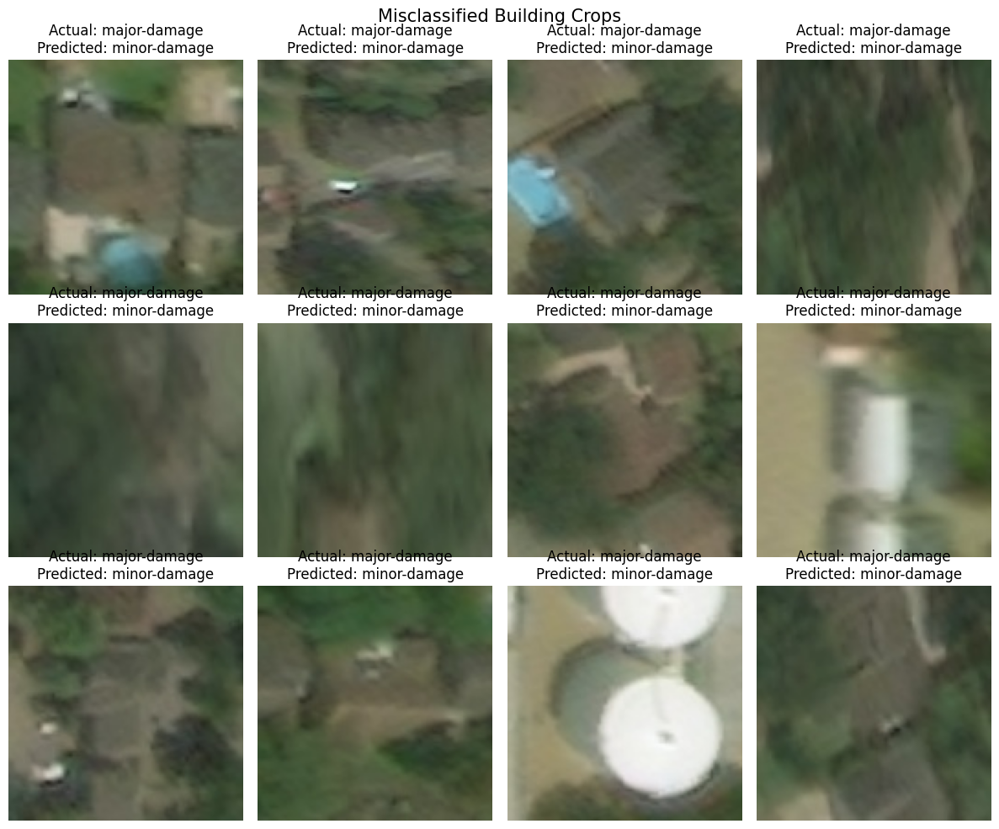

In [33]:

import matplotlib.pyplot as plt
import random

# Reproducible sample of misclassified examples
random.seed(42)
sample_indices = random.sample(
    wrong_indices, min(12, len(wrong_indices))
)

fig, axes = plt.subplots(3, 4, figsize=(12, 10))
axes = axes.flatten()

for ax, idx in zip(axes, sample_indices):
    image, label = val_dataset[idx]

    # Undo ImageNet normalization for display
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    image = (image * std + mean).clamp(0, 1)

    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title("Actual: major-damage\nPredicted: minor-damage")
    ax.axis("off")

plt.suptitle("Misclassified Building Crops", fontsize=15)
plt.tight_layout()
plt.show()


In [34]:

import pandas as pd

val_df = pd.read_csv(
    "/content/drive/MyDrive/T229/reports/val_buildings.csv"
)

print("Columns:")
print(val_df.columns.tolist())

print("\nFirst 3 validation records:")
display(val_df.head(3))


Columns:
['scene_id', 'image_path', 'label', 'polygon_wkt']

First 3 validation records:


,scene_id,image_path,label,polygon_wkt
0,hurricane-harvey_00000132,/content/drive/MyDrive/T229/data/train/images/...,minor-damage,"POLYGON ((380.7673822794917 1022.988691617148,..."
1,hurricane-florence_00000091,/content/drive/MyDrive/T229/data/train/images/...,no-damage,"POLYGON ((614.9052939733259 151.8742402001954,..."
2,hurricane-michael_00000067,/content/drive/MyDrive/T229/data/train/images/...,destroyed,"POLYGON ((214.5574423012306 168.0310925103237,..."


In [35]:

import os
import glob

image_dir = "/content/drive/MyDrive/T229/data/train/images"

# Inspect one validation record
row = val_df.iloc[0]
print("Scene ID:", row["scene_id"])
print("Post-disaster image path:", row["image_path"])
print("Post image exists:", os.path.exists(row["image_path"]))

# Search for image files associated with this scene
scene_id = row["scene_id"]
matches = glob.glob(os.path.join(image_dir, f"*{scene_id}*"))

print("\nMatching files:")
for path in matches[:10]:
    print(os.path.basename(path))

print("\nTotal matches:", len(matches))


Scene ID: hurricane-harvey_00000132
Post-disaster image path: /content/drive/MyDrive/T229/data/train/images/hurricane-harvey_00000132_post_disaster.png
Post image exists: True

Matching files:
hurricane-harvey_00000132_post_disaster.png
hurricane-harvey_00000132_pre_disaster.png

Total matches: 2


Pre-disaster dimensions: (1024, 1024)
Post-disaster dimensions: (1024, 1024)
Same dimensions: True


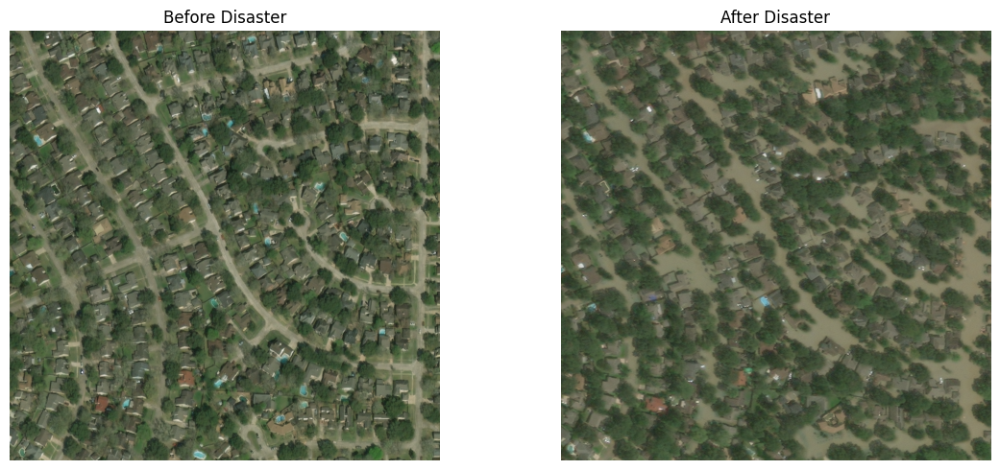

In [36]:

from PIL import Image
import os

row = val_df.iloc[0]

post_path = row["image_path"]
pre_path = post_path.replace(
    "_post_disaster.png",
    "_pre_disaster.png"
)

pre_image = Image.open(pre_path).convert("RGB")
post_image = Image.open(post_path).convert("RGB")

print("Pre-disaster dimensions:", pre_image.size)
print("Post-disaster dimensions:", post_image.size)
print("Same dimensions:", pre_image.size == post_image.size)

# Display both images side by side
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(pre_image)
axes[0].set_title("Before Disaster")
axes[0].axis("off")

axes[1].imshow(post_image)
axes[1].set_title("After Disaster")
axes[1].axis("off")

plt.tight_layout()
plt.show()


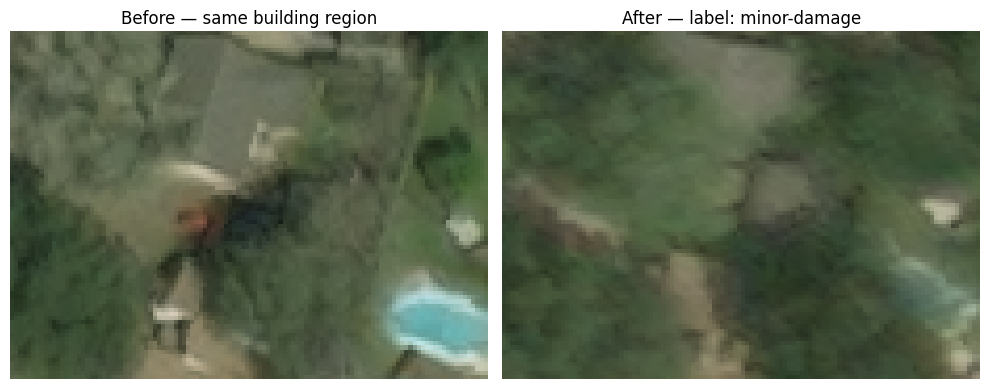

Building label: minor-damage
Crop dimensions: (114, 83)


In [37]:

from shapely import wkt
from PIL import Image
import matplotlib.pyplot as plt

row = val_df.iloc[0]

post_path = row["image_path"]
pre_path = post_path.replace(
    "_post_disaster.png",
    "_pre_disaster.png"
)

polygon = wkt.loads(row["polygon_wkt"])
minx, miny, maxx, maxy = polygon.bounds

# Add 32 pixels of context around the building
padding = 32
left = max(0, int(minx) - padding)
top = max(0, int(miny) - padding)
right = min(1024, int(maxx) + padding + 1)
bottom = min(1024, int(maxy) + padding + 1)

pre_img = Image.open(pre_path).convert("RGB")
post_img = Image.open(post_path).convert("RGB")

pre_crop = pre_img.crop((left, top, right, bottom))
post_crop = post_img.crop((left, top, right, bottom))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(pre_crop)
axes[0].set_title("Before — same building region")
axes[1].imshow(post_crop)
axes[1].set_title(f"After — label: {row['label']}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Building label:", row["label"])
print("Crop dimensions:", pre_crop.size)


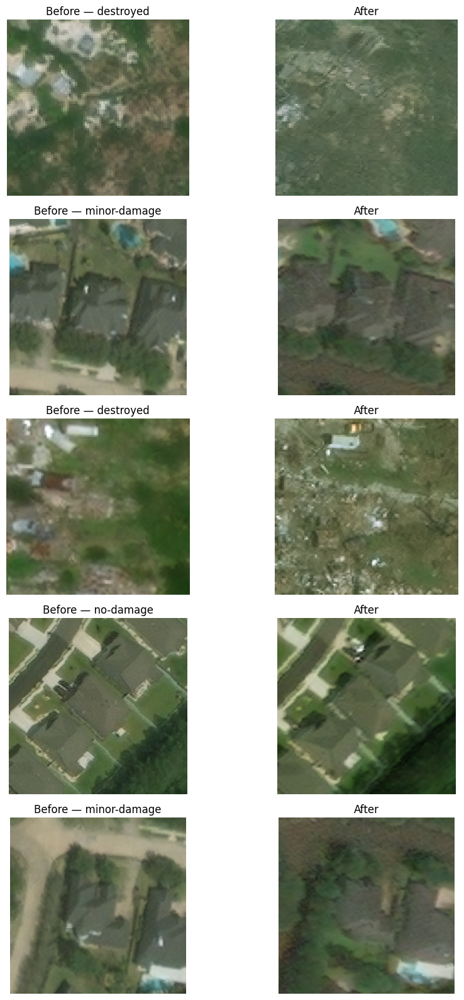

In [38]:

import random
import matplotlib.pyplot as plt
from PIL import Image
from shapely import wkt

random.seed(42)
sample_rows = val_df.sample(
    n=min(5, len(val_df)), random_state=42
)

fig, axes = plt.subplots(5, 2, figsize=(10, 16))

for i, (_, row) in enumerate(sample_rows.iterrows()):
    post_path = row["image_path"]
    pre_path = post_path.replace(
        "_post_disaster.png", "_pre_disaster.png"
    )

    polygon = wkt.loads(row["polygon_wkt"])
    minx, miny, maxx, maxy = polygon.bounds

    pad = 40
    left = max(0, int(minx) - pad)
    top = max(0, int(miny) - pad)
    right = min(1024, int(maxx) + pad + 1)
    bottom = min(1024, int(maxy) + pad + 1)

    pre = Image.open(pre_path).convert("RGB")
    post = Image.open(post_path).convert("RGB")

    axes[i, 0].imshow(pre.crop((left, top, right, bottom)))
    axes[i, 0].set_title(f"Before — {row['label']}")
    axes[i, 1].imshow(post.crop((left, top, right, bottom)))
    axes[i, 1].set_title("After")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


Pre-image features: 3000
Post-image features: 3000
Good feature matches: 15
RANSAC inliers: 4
Inlier ratio: 0.267


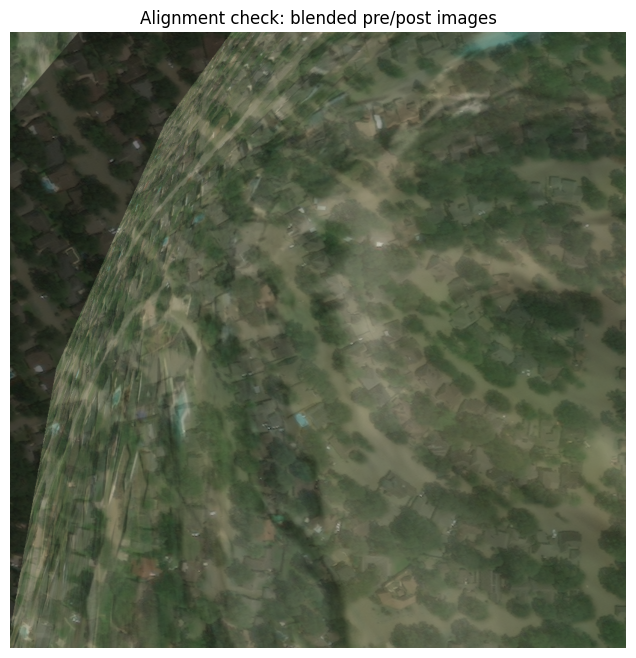

In [39]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

row = val_df.iloc[0]

post_path = row["image_path"]
pre_path = post_path.replace(
    "_post_disaster.png",
    "_pre_disaster.png"
)

pre = cv2.imread(pre_path)
post = cv2.imread(post_path)

pre_gray = cv2.cvtColor(pre, cv2.COLOR_BGR2GRAY)
post_gray = cv2.cvtColor(post, cv2.COLOR_BGR2GRAY)

# Detect and match visual features
orb = cv2.ORB_create(nfeatures=3000)

kp_pre, des_pre = orb.detectAndCompute(pre_gray, None)
kp_post, des_post = orb.detectAndCompute(post_gray, None)

print("Pre-image features:", len(kp_pre))
print("Post-image features:", len(kp_post))

if des_pre is not None and des_post is not None:
    matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
    pairs = matcher.knnMatch(des_pre, des_post, k=2)

    good = [
        m for m, n in pairs
        if m.distance < 0.75 * n.distance
    ]

    print("Good feature matches:", len(good))

    if len(good) >= 10:
        pts_pre = np.float32(
            [kp_pre[m.queryIdx].pt for m in good]
        ).reshape(-1, 1, 2)

        pts_post = np.float32(
            [kp_post[m.trainIdx].pt for m in good]
        ).reshape(-1, 1, 2)

        H, inliers = cv2.findHomography(
            pts_pre, pts_post, cv2.RANSAC, 5.0
        )

        if H is not None:
            print("RANSAC inliers:", int(inliers.sum()))
            print("Inlier ratio:", round(float(inliers.mean()), 3))

            aligned_pre = cv2.warpPerspective(
                pre, H, (post.shape[1], post.shape[0])
            )

            comparison = cv2.addWeighted(
                aligned_pre, 0.5, post, 0.5, 0
            )

            plt.figure(figsize=(8, 8))
            plt.imshow(cv2.cvtColor(comparison, cv2.COLOR_BGR2RGB))
            plt.title("Alignment check: blended pre/post images")
            plt.axis("off")
            plt.show()
        else:
            print("Could not estimate a reliable homography.")
    else:
        print("Too few matches to estimate alignment reliably.")
else:
    print("Feature descriptors could not be computed.")


In [40]:

# Test a second scene without applying any image transformation

row2 = val_df.iloc[10]

post_path2 = row2["image_path"]
pre_path2 = post_path2.replace(
    "_post_disaster.png",
    "_pre_disaster.png"
)

pre2 = cv2.imread(pre_path2)
post2 = cv2.imread(post_path2)

pre_gray2 = cv2.cvtColor(pre2, cv2.COLOR_BGR2GRAY)
post_gray2 = cv2.cvtColor(post2, cv2.COLOR_BGR2GRAY)

kp1, des1 = orb.detectAndCompute(pre_gray2, None)
kp2, des2 = orb.detectAndCompute(post_gray2, None)

print("Scene:", row2["scene_id"])
print("Label:", row2["label"])
print("Pre-image features:", len(kp1))
print("Post-image features:", len(kp2))

if des1 is not None and des2 is not None:
    matches = cv2.BFMatcher(
        cv2.NORM_HAMMING
    ).knnMatch(des1, des2, k=2)

    good2 = [
        m for m, n in matches
        if m.distance < 0.75 * n.distance
    ]

    print("Good feature matches:", len(good2))

    if len(good2) >= 10:
        p1 = np.float32(
            [kp1[m.queryIdx].pt for m in good2]
        ).reshape(-1, 1, 2)
        p2 = np.float32(
            [kp2[m.trainIdx].pt for m in good2]
        ).reshape(-1, 1, 2)

        H2, mask2 = cv2.findHomography(
            p1, p2, cv2.RANSAC, 5.0
        )

        if H2 is not None:
            print("RANSAC inliers:", int(mask2.sum()))
            print("Inlier ratio:", round(float(mask2.mean()), 3))
        else:
            print("Homography estimation failed.")
else:
    print("Feature descriptors unavailable.")


Scene: hurricane-florence_00000404
Label: minor-damage
Pre-image features: 2603
Post-image features: 1922
Good feature matches: 37
RANSAC inliers: 23
Inlier ratio: 0.622


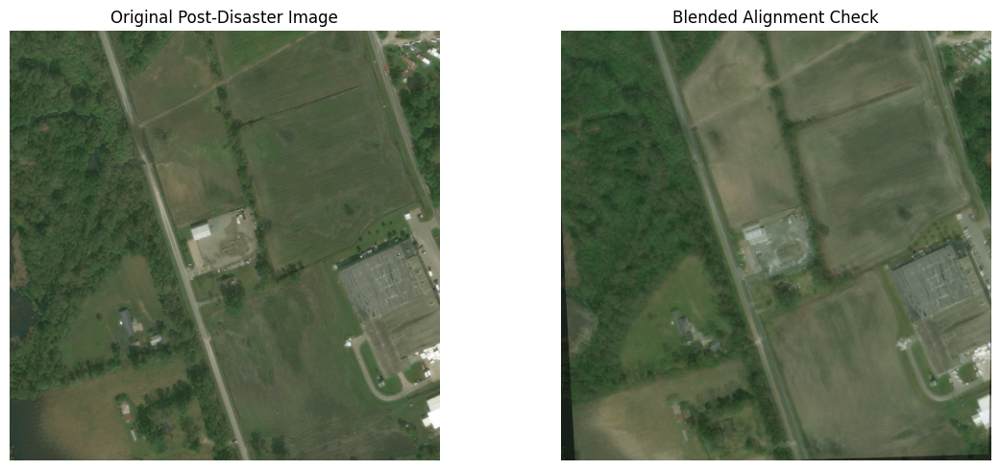

Estimated homography:
[[ 1.06661383e+00  5.93288901e-02 -2.39768155e+01]
 [ 3.81998477e-04  1.10913592e+00 -1.60735704e+01]
 [ 3.03727557e-05  7.68263138e-05  1.00000000e+00]]


In [41]:

# Visualize the second scene's estimated alignment

aligned_pre2 = cv2.warpPerspective(
    pre2,
    H2,
    (post2.shape[1], post2.shape[0])
)

blended2 = cv2.addWeighted(
    aligned_pre2, 0.5,
    post2, 0.5,
    0
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(
    cv2.cvtColor(post2, cv2.COLOR_BGR2RGB)
)
axes[0].set_title("Original Post-Disaster Image")
axes[0].axis("off")

axes[1].imshow(
    cv2.cvtColor(blended2, cv2.COLOR_BGR2RGB)
)
axes[1].set_title("Blended Alignment Check")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Estimated homography:")
print(H2)


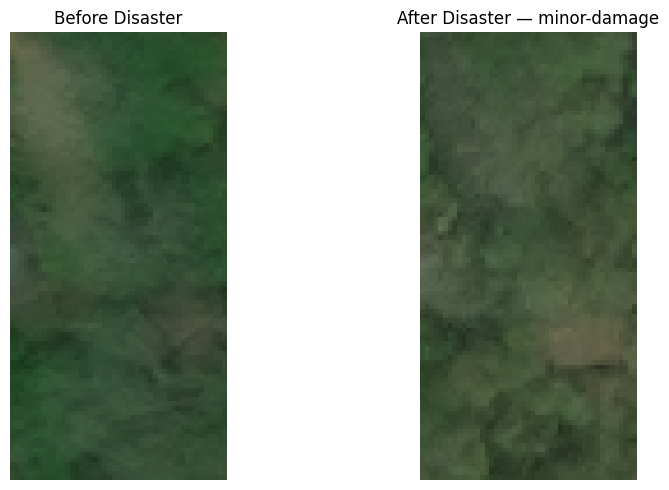

Scene: hurricane-florence_00000404
Label: minor-damage
Crop size: 47 x 97


In [42]:

# Inspect a building from the Florence scene
row = val_df[
    val_df["scene_id"] == "hurricane-florence_00000404"
].iloc[0]

post_path = row["image_path"]
pre_path = post_path.replace(
    "_post_disaster.png", "_pre_disaster.png"
)

polygon = wkt.loads(row["polygon_wkt"])
minx, miny, maxx, maxy = polygon.bounds

pad = 40
left = max(0, int(minx) - pad)
top = max(0, int(miny) - pad)
right = min(1024, int(maxx) + pad + 1)
bottom = min(1024, int(maxy) + pad + 1)

pre_img = Image.open(pre_path).convert("RGB")
post_img = Image.open(post_path).convert("RGB")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(pre_img.crop((left, top, right, bottom)))
axes[0].set_title("Before Disaster")
axes[1].imshow(post_img.crop((left, top, right, bottom)))
axes[1].set_title(f"After Disaster — {row['label']}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Scene:", row["scene_id"])
print("Label:", row["label"])
print("Crop size:", right - left, "x", bottom - top)


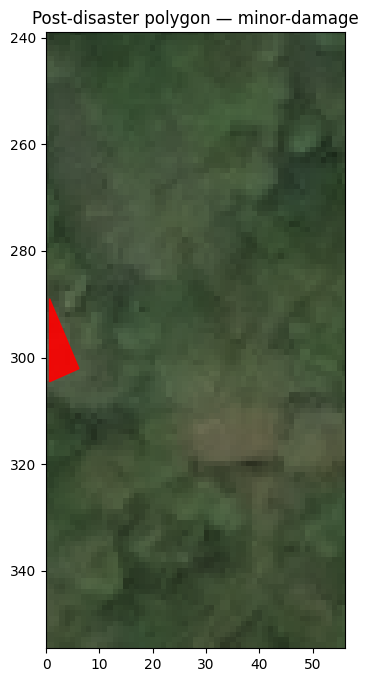

Polygon bounds: (0.6410710506094792, 288.9774358621206, 6.161099466914714, 304.5583293729878)
Polygon area: 43.00334752349167


In [43]:

import matplotlib.pyplot as plt
from PIL import Image
from shapely import wkt
from shapely.plotting import plot_polygon

row = val_df[
    val_df["scene_id"] == "hurricane-florence_00000404"
].iloc[0]

img = Image.open(row["image_path"]).convert("RGB")
polygon = wkt.loads(row["polygon_wkt"])

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img)
plot_polygon(
    polygon,
    ax=ax,
    add_points=False,
    color="red",
    alpha=0.9
)

ax.set_xlim(
    max(0, polygon.bounds[0] - 50),
    min(img.width, polygon.bounds[2] + 50)
)
ax.set_ylim(
    min(img.height, polygon.bounds[3] + 50),
    max(0, polygon.bounds[1] - 50)
)

ax.set_title(f"Post-disaster polygon — {row['label']}")
plt.show()

print("Polygon bounds:", polygon.bounds)
print("Polygon area:", polygon.area)


In [44]:

from shapely import wkt

scene_df = val_df[
    val_df["scene_id"] == "hurricane-florence_00000404"
].copy()

def polygon_info(geometry_text):
    poly = wkt.loads(geometry_text)
    minx, miny, maxx, maxy = poly.bounds
    return pd.Series({
        "width": maxx - minx,
        "height": maxy - miny,
        "area": poly.area,
        "minx": minx,
        "miny": miny,
        "maxx": maxx,
        "maxy": maxy
    })

scene_df = pd.concat(
    [scene_df, scene_df["polygon_wkt"].apply(polygon_info)],
    axis=1
)

# Prefer larger polygons with enough space from image edges
candidates = scene_df[
    (scene_df["width"] >= 15) &
    (scene_df["height"] >= 15) &
    (scene_df["minx"] >= 40) &
    (scene_df["miny"] >= 40) &
    (scene_df["maxx"] <= 984) &
    (scene_df["maxy"] <= 984)
].sort_values("area", ascending=False)

print("Candidates found:", len(candidates))
display(
    candidates[
        ["label", "width", "height", "area", "polygon_wkt"]
    ].head(5)
)


Candidates found: 1


,label,width,height,area,polygon_wkt
1074,minor-damage,28.265159,22.980189,382.416037,"POLYGON ((65.65775351738084 228.4328662341168,..."


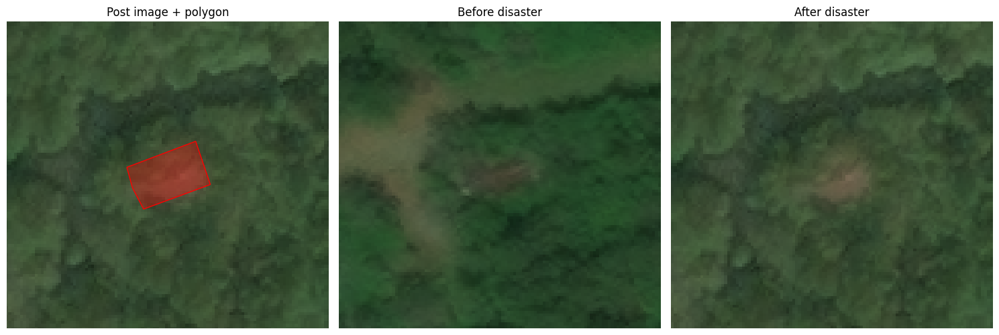

Scene: hurricane-florence_00000404
Label: minor-damage
Crop size: 109 x 104


In [45]:

from shapely import wkt
from shapely.plotting import plot_polygon
from PIL import Image
import matplotlib.pyplot as plt

row = candidates.iloc[0]

post_path = row["image_path"]
pre_path = post_path.replace(
    "_post_disaster.png", "_pre_disaster.png"
)

polygon = wkt.loads(row["polygon_wkt"])
minx, miny, maxx, maxy = polygon.bounds

pad = 40
left = max(0, int(minx) - pad)
top = max(0, int(miny) - pad)
right = min(1024, int(maxx) + pad + 1)
bottom = min(1024, int(maxy) + pad + 1)

pre_img = Image.open(pre_path).convert("RGB")
post_img = Image.open(post_path).convert("RGB")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(post_img)
plot_polygon(polygon, ax=axes[0], add_points=False, color="red")
axes[0].set_xlim(left, right)
axes[0].set_ylim(bottom, top)
axes[0].set_title("Post image + polygon")

axes[1].imshow(pre_img.crop((left, top, right, bottom)))
axes[1].set_title("Before disaster")

axes[2].imshow(post_img.crop((left, top, right, bottom)))
axes[2].set_title("After disaster")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Scene:", row["scene_id"])
print("Label:", row["label"])
print("Crop size:", right-left, "x", bottom-top)


In [46]:

from shapely import wkt
import pandas as pd

def inspect_polygon(wkt_text):
    poly = wkt.loads(wkt_text)
    minx, miny, maxx, maxy = poly.bounds
    return pd.Series({
        "width": maxx - minx,
        "height": maxy - miny,
        "area": poly.area,
        "touches_edge": (
            minx < 2 or miny < 2 or
            maxx > 1022 or maxy > 1022
        )
    })

polygon_stats = val_df["polygon_wkt"].apply(inspect_polygon)
val_quality = pd.concat([val_df, polygon_stats], axis=1)

print("Validation buildings:", len(val_quality))
print("Polygons touching image edges:",
      int(val_quality["touches_edge"].sum()))
print("Polygons smaller than 8 px in either dimension:",
      int(((val_quality["width"] < 8) |
           (val_quality["height"] < 8)).sum()))
print("Polygons with area below 100 px²:",
      int((val_quality["area"] < 100).sum()))

print("\nPolygon dimensions:")
display(val_quality[["width", "height", "area"]].describe())


Validation buildings: 2886
Polygons touching image edges: 268
Polygons smaller than 8 px in either dimension: 108
Polygons with area below 100 px²: 246

Polygon dimensions:


,width,height,area
count,2886.000000,2886.000000,2886.000000
mean,35.314581,34.940282,1026.853748
std,24.607161,23.087373,1863.207593
min,3.253985,3.885462,17.322183
25%,19.370610,18.767595,253.379866
50%,33.284498,33.911722,807.491048
75%,44.784223,45.719024,1312.795196
max,335.574141,512.203532,59462.963157


In [47]:

quality_summary = (
    val_quality.groupby("label")
    .agg(
        buildings=("label", "size"),
        edge_polygons=("touches_edge", "sum"),
        tiny_polygons=(
            "width",
            lambda s: int(
                ((s < 8) |
                 (val_quality.loc[s.index, "height"] < 8)).sum()
            )
        ),
        small_area=("area", lambda s: int((s < 100).sum())),
        median_width=("width", "median"),
        median_height=("height", "median")
    )
)

quality_summary["edge_percent"] = (
    100 * quality_summary["edge_polygons"] /
    quality_summary["buildings"]
).round(1)

quality_summary["tiny_percent"] = (
    100 * quality_summary["tiny_polygons"] /
    quality_summary["buildings"]
).round(1)

quality_summary["small_area_percent"] = (
    100 * quality_summary["small_area"] /
    quality_summary["buildings"]
).round(1)

display(quality_summary.round(2))


,buildings,edge_polygons,tiny_polygons,small_area,median_width,median_height,edge_percent,tiny_percent,small_area_percent
label,,,,,,,,,
destroyed,779,44,71,167,17.59,16.45,5.6,9.1,21.4
major-damage,816,82,13,33,37.16,39.19,10.0,1.6,4.0
minor-damage,640,79,5,7,42.49,45.17,12.3,0.8,1.1
no-damage,651,63,19,39,34.61,32.73,9.7,2.9,6.0


In [48]:

# Compare polygon quality for correct vs incorrect predictions

val_quality = val_quality.reset_index(drop=True)

val_quality["actual_idx"] = [
    val_dataset.class_to_idx[label]
    for label in val_quality["label"]
]

val_quality["predicted_idx"] = all_predictions

val_quality["prediction_result"] = (
    val_quality["actual_idx"] ==
    val_quality["predicted_idx"]
).map({True: "Correct", False: "Incorrect"})

error_summary = (
    val_quality.groupby("prediction_result")
    .agg(
        buildings=("label", "size"),
        median_width=("width", "median"),
        median_height=("height", "median"),
        median_area=("area", "median"),
        edge_percent=("touches_edge",
                      lambda s: 100 * s.mean()),
        tiny_percent=("width",
                      lambda s: 100 * (
                          (s < 8) |
                          (val_quality.loc[s.index, "height"] < 8)
                      ).mean()),
    )
    .round(2)
)

display(error_summary)


,buildings,median_width,median_height,median_area,edge_percent,tiny_percent
prediction_result,,,,,,
Correct,715,34.42,35.65,890.26,9.37,4.90
Incorrect,2171,33.02,33.19,787.81,9.26,3.36


In [49]:

import numpy as np

# Recompute predictions directly from the best checkpoint
best_model.eval()
fresh_labels = []
fresh_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = best_model(images)

        fresh_predictions.extend(
            outputs.argmax(dim=1).cpu().numpy()
        )
        fresh_labels.extend(labels.numpy())

fresh_labels = np.array(fresh_labels)
fresh_predictions = np.array(fresh_predictions)

# ImageFolder dataset order should match val_loader order
csv_labels = np.array([
    val_dataset.class_to_idx[label]
    for label in val_df["label"]
])

print("Validation examples:", len(fresh_labels))
print("CSV rows:", len(csv_labels))
print("Loader labels match CSV order:",
      np.array_equal(fresh_labels, csv_labels))

print("Fresh accuracy:",
      round(float(np.mean(fresh_labels == fresh_predictions)), 4))

print("Fresh correct predictions:",
      int(np.sum(fresh_labels == fresh_predictions)))


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Validation examples: 2886
CSV rows: 2886
Loader labels match CSV order: False
Fresh accuracy: 0.8177
Fresh correct predictions: 2360


In [50]:

import os
import numpy as np
import pandas as pd

# Map each validation image filename to its true label and prediction.
# ImageFolder stores image paths in dataset.samples.
image_paths = [path for path, _ in val_dataset.samples]

pred_df = pd.DataFrame({
    "image_path": image_paths,
    "actual_idx": fresh_labels,
    "predicted_idx": fresh_predictions
})

idx_to_class = {
    idx: name
    for name, idx in val_dataset.class_to_idx.items()
}

pred_df["actual_label"] = pred_df["actual_idx"].map(idx_to_class)
pred_df["predicted_label"] = pred_df["predicted_idx"].map(idx_to_class)

# Join predictions to CSV metadata using the image crop filename.
val_quality["crop_path"] = val_quality["image_path"].apply(
    lambda p: os.path.join(
        "/content/drive/MyDrive/T229/data/building_crops/val",
        val_quality.loc[val_quality["image_path"] == p, "label"].iloc[0],
        os.path.basename(p).replace("_post_disaster.png", ".jpg")
    )
) if False else None

# Use crop filenames to match each prediction to its metadata.
# The crop filenames retain the source image name and polygon identifier.
pred_df["crop_name"] = pred_df["image_path"].apply(os.path.basename)
print("Example crop filenames:")
print(pred_df["crop_name"].head().to_list())

print("\nPrediction counts:")
print("Correct:", int((pred_df["actual_idx"] == pred_df["predicted_idx"]).sum()))
print("Incorrect:", int((pred_df["actual_idx"] != pred_df["predicted_idx"]).sum()))


Example crop filenames:
['1001_hurricane-matthew_00000336.jpg', '1003_hurricane-matthew_00000398.jpg', '1004_hurricane-matthew_00000380.jpg', '1010_hurricane-matthew_00000205.jpg', '1011_hurricane-matthew_00000186.jpg']

Prediction counts:
Correct: 2360
Incorrect: 526


In [51]:

# # Rebuild the exact crop filename for each validation CSV row
# val_quality = val_quality.reset_index(drop=True)

# val_quality["crop_name"] = [
#     f"{i}_{os.path.basename(path).replace('_post_disaster.png', '')}.jpg"
#     for i, path in enumerate(val_quality["image_path"])
# ]

# # Match metadata to predictions using the exact crop filename
# matched = val_quality.merge(
#     pred_df,
#     on="crop_name",
#     how="inner",
#     suffixes=("_csv", "_pred")
# )

# print("CSV validation rows:", len(val_quality))
# print("Matched prediction rows:", len(matched))

# if len(matched) == len(val_quality):
#     matched["prediction_result"] = np.where(
#         matched["actual_idx"] == matched["predicted_idx"],
#         "Correct",
#         "Incorrect"
#     )

#     display(
#         matched.groupby("prediction_result").agg(
#             buildings=("label", "size"),
#             median_width=("width", "median"),
#             median_height=("height", "median"),
#             median_area=("area", "median"),
#             edge_percent=("touches_edge", lambda s: 100 * s.mean())
#         ).round(2)
#     )
# else:
#     print("Filename conventions differ; inspect these examples:")
#     print("CSV:", val_quality["crop_name"].head().to_list())
#     print("Predictions:", pred_df["crop_name"].head().to_list())


In [52]:

# Check the column names created by the merge
print(matched.columns.tolist())


NameError: name 'matched' is not defined

In [53]:

# The CSV label is the ground truth.
# The prediction table contains the model's predicted class.
matched["prediction_result"] = np.where(
    matched["label"] == matched["predicted_label"],
    "Correct",
    "Incorrect"
)

error_summary = (
    matched.groupby("prediction_result")
    .agg(
        buildings=("label", "size"),
        median_width=("width", "median"),
        median_height=("height", "median"),
        median_area=("area", "median"),
        edge_percent=("touches_edge", lambda s: 100 * s.mean()),
        tiny_percent=("width", lambda s: 100 * (
            (s < 8) |
            (matched.loc[s.index, "height"] < 8)
        ).mean())
    )
    .round(2)
)

display(error_summary)


NameError: name 'matched' is not defined

In [61]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_names = [
    "destroyed",
    "major-damage",
    "minor-damage",
    "no-damage"
]

cm = confusion_matrix(
    matched["actual_label"],
    matched["predicted_label"],
    labels=class_names
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=35)
plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()


NameError: name 'matched' is not defined

In [ ]:

import os
import matplotlib.pyplot as plt
from PIL import Image

# Find major-damage buildings predicted as minor-damage
errors = matched[
    (matched["actual_label"] == "major-damage") &
    (matched["predicted_label"] == "minor-damage")
].head(12)

print("Major → minor errors displayed:", len(errors))

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for ax, (_, row) in zip(axes, errors.iterrows()):
    img = Image.open(row["image_path_pred"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(
        f"True: major\nPredicted: minor",
        fontsize=9
    )
    ax.axis("off")

for ax in axes[len(errors):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [62]:

import os
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

# Reuse the same major -> minor errors
errors = matched[
    (matched["actual_label"] == "major-damage") &
    (matched["predicted_label"] == "minor-damage")
].head(6)

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.flatten()

for ax, (_, row) in zip(axes, errors.iterrows()):
    image_path = row["image_path_csv"]
    image = Image.open(image_path).convert("RGB")

    # Read the building polygon from the original annotation
    from shapely import wkt
    polygon = wkt.loads(row["polygon_wkt"])
    minx, miny, maxx, maxy = polygon.bounds

    # Expand the crop to provide 3x more context
    cx, cy = (minx + maxx) / 2, (miny + maxy) / 2
    half_w = max((maxx - minx) * 1.5, 48)
    half_h = max((maxy - miny) * 1.5, 48)

    left = max(0, int(cx - half_w))
    top = max(0, int(cy - half_h))
    right = min(image.width, int(cx + half_w))
    bottom = min(image.height, int(cy + half_h))

    crop = image.crop((left, top, right, bottom))
    ax.imshow(crop)
    ax.set_title("True: major | Predicted: minor")
    ax.axis("off")

plt.tight_layout()
plt.show()


NameError: name 'matched' is not defined

In [ ]:
project_root = "/content/drive/MyDrive/T229"

train_csv = f"{project_root}/reports/train_buildings.csv"
val_csv = f"{project_root}/reports/val_buildings.csv"

train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)

print("\nColumns:")
print(train_df.columns.tolist())

print("\nFirst training row:")
display(train_df.head(1))


In [ ]:

# from PIL import Image
# from shapely import wkt

# project_root = "/content/drive/MyDrive/T229"

# output_root = f"{project_root}/data/building_crops_context"
# padding = 48
# output_size = (128, 128)

# splits = {
#     "train": f"{project_root}/reports/train_buildings.csv",
#     "val": f"{project_root}/reports/val_buildings.csv",
# }

# for split, csv_path in splits.items():
#     df = pd.read_csv(csv_path)
#     print(f"\nProcessing {split}: {len(df)} buildings")

#     for _, row in tqdm(df.iterrows(), total=len(df)):
#         image_path = row["image_path"]
#         label = row["label"]

#         # Read the original post-disaster image
#         with Image.open(image_path) as source:
#             image = source.convert("RGB")
#             polygon = wkt.loads(row["polygon_wkt"])
#             minx, miny, maxx, maxy = polygon.bounds

#             # Expand the building bounding box
#             left = max(0, int(minx) - padding)
#             top = max(0, int(miny) - padding)
#             right = min(image.width, int(maxx) + padding)
#             bottom = min(image.height, int(maxy) + padding)

#             if right <= left or bottom <= top:
#                 continue

#             crop = image.crop((left, top, right, bottom))
#             crop = crop.resize(output_size, Image.Resampling.BILINEAR)

#             # Keep filenames consistent with the original dataset
#             filename = f"{row.name}_{row['scene_id']}.jpg"
#             save_dir = os.path.join(output_root, split, label)
#             os.makedirs(save_dir, exist_ok=True)
#             crop.save(os.path.join(save_dir, filename), quality=95)

#     print(f"Finished {split}")

# print("\nLarger-context crop generation complete!")
# print("Output:", output_root)


In [ ]:
context_root = "/content/drive/MyDrive/T229/data/building_crops_context"
classes = [
    "destroyed",
    "major-damage",
    "minor-damage",
    "no-damage"
]

for split in ["train", "val"]:
    print(f"\n{split.upper()}")

    total = 0
    for cls in classes:
        folder = os.path.join(context_root, split, cls)
        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])
        print(f"{cls}: {count}")
        total += count

    print("Total:", total)


In [ ]:

import os
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

context_root = "/content/drive/MyDrive/T229/data/building_crops_context"

image_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

context_train_dataset = datasets.ImageFolder(
    os.path.join(context_root, "train"),
    transform=image_transform
)

context_val_dataset = datasets.ImageFolder(
    os.path.join(context_root, "val"),
    transform=image_transform
)

print("Class mapping:", context_train_dataset.class_to_idx)
print("Train examples:", len(context_train_dataset))
print("Validation examples:", len(context_val_dataset))

batch_size = 32

context_train_loader = DataLoader(
    context_train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

context_val_loader = DataLoader(
    context_val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(context_train_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)


In [ ]:

import os
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

# Fresh pretrained ResNet-18
weights = models.ResNet18_Weights.DEFAULT
context_model = models.resnet18(weights=weights)

context_model.fc = nn.Linear(
    context_model.fc.in_features, 4
)

context_model = context_model.to(device)

criterion = nn.CrossEntropyLoss()

context_optimizer = torch.optim.AdamW(
    context_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

context_checkpoint_dir = (
    "/content/drive/MyDrive/T229/checkpoints"
)
os.makedirs(context_checkpoint_dir, exist_ok=True)

context_best_path = os.path.join(
    context_checkpoint_dir,
    "resnet18_context_best.pth"
)

print("Model initialized successfully.")
print("Checkpoint:", context_best_path)


In [ ]:
# from sklearn.metrics import accuracy_score, f1_score

# history_context = []
# best_context_f1 = -1.0
# best_context_state = None
# num_epochs = 3

# for epoch in range(num_epochs):
#     # Training
#     context_model.train()
#     train_loss_sum = 0.0
#     train_count = 0

#     for images, labels in tqdm(
#         context_train_loader, desc=f"Epoch {epoch+1} training"
#     ):
#         images = images.to(device)
#         labels = labels.to(device)

#         context_optimizer.zero_grad()
#         outputs = context_model(images)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         context_optimizer.step()

#         train_loss_sum += loss.item() * labels.size(0)
#         train_count += labels.size(0)

#     train_loss = train_loss_sum / train_count

#     # Validation
#     context_model.eval()
#     val_loss_sum = 0.0
#     val_count = 0
#     all_labels = []
#     all_preds = []

#     with torch.no_grad():
#         for images, labels in tqdm(
#             context_val_loader, desc=f"Epoch {epoch+1} validation"
#         ):
#             images = images.to(device)
#             labels = labels.to(device)

#             outputs = context_model(images)
#             loss = criterion(outputs, labels)
#             predictions = outputs.argmax(dim=1)

#             val_loss_sum += loss.item() * labels.size(0)
#             val_count += labels.size(0)

#             all_labels.extend(labels.cpu().tolist())
#             all_preds.extend(predictions.cpu().tolist())

#     val_loss = val_loss_sum / val_count
#     val_accuracy = accuracy_score(all_labels, all_preds)
#     val_f1 = f1_score(
#         all_labels, all_preds, average="macro"
#     )

#     history_context.append({
#         "epoch": epoch + 1,
#         "train_loss": train_loss,
#         "val_loss": val_loss,
#         "val_accuracy": val_accuracy,
#         "val_macro_f1": val_f1
#     })

#     print(
#         f"\nEpoch {epoch+1}/{num_epochs} | "
#         f"Train loss: {train_loss:.4f} | "
#         f"Val loss: {val_loss:.4f} | "
#         f"Val accuracy: {val_accuracy:.4f} | "
#         f"Val macro-F1: {val_f1:.4f}"
#     )

#     if val_f1 > best_context_f1:
#         best_context_f1 = val_f1
#         best_context_state = copy.deepcopy(
#             context_model.state_dict()
#         )

#         torch.save({
#             "epoch": epoch + 1,
#             "model_state_dict": best_context_state,
#             "class_to_idx": context_train_dataset.class_to_idx,
#             "val_macro_f1": best_context_f1
#         }, context_best_path)

#         print("Best context checkpoint saved.")

# # Save training history
# history_path = (
#     "/content/drive/MyDrive/T229/reports/"
#     "resnet18_context_training_history.csv"
# )
# pd.DataFrame(history_context).to_csv(history_path, index=False)

# print("\nTraining complete.")
# print("Best validation macro-F1:", round(best_context_f1, 4))
# print("History saved:", history_path)
# print("Best checkpoint:", context_best_path)


In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

checkpoint = torch.load(
    "/content/drive/MyDrive/T229/checkpoints/resnet18_context_best.pth",
    map_location=device,
    weights_only=False
)

context_model.load_state_dict(checkpoint["model_state_dict"])
context_model.eval()

all_labels = []
all_preds = []

with torch.no_grad():
    for images, labels in context_val_loader:
        images = images.to(device)
        outputs = context_model(images)
        preds = outputs.argmax(dim=1)

        all_labels.extend(labels.tolist())
        all_preds.extend(preds.cpu().tolist())

class_names = [
    name for name, index in sorted(
        context_train_dataset.class_to_idx.items(),
        key=lambda item: item[1]
    )
]

print("Best checkpoint epoch:", checkpoint["epoch"])
print("Validation macro-F1:", checkpoint["val_macro_f1"])
print("\nClassification report:\n")
print(classification_report(
    all_labels, all_preds,
    target_names=class_names,
    digits=4
))

ConfusionMatrixDisplay.from_predictions(
    all_labels,
    all_preds,
    display_labels=class_names,
    cmap="Blues",
    values_format="d",
    xticks_rotation=35
)
plt.title("Larger-Context Model — Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

project_root = "/content/drive/MyDrive/T229"

baseline_root = f"{project_root}/data/building_crops"
context_root = f"{project_root}/data/building_crops_context"

baseline_val = pd.read_csv(
    f"{project_root}/reports/val_buildings.csv"
)

context_val = pd.read_csv(
    f"{project_root}/reports/val_buildings.csv"
)

# ImageFolder sorts files alphabetically within each class.
# Check class-wise filenames and counts in both datasets.
for cls in sorted(os.listdir(f"{baseline_root}/val")):
    old_dir = os.path.join(baseline_root, "val", cls)
    new_dir = os.path.join(context_root, "val", cls)

    old_files = sorted(
        f for f in os.listdir(old_dir)
        if f.lower().endswith(".jpg")
    )
    new_files = sorted(
        f for f in os.listdir(new_dir)
        if f.lower().endswith(".jpg")
    )

    print(f"\n{cls}")
    print("Baseline:", len(old_files))
    print("Context:", len(new_files))
    print("Same filenames:", old_files == new_files)

print("\nValidation CSV rows:", len(baseline_val))
print("Unique validation scenes:", baseline_val["scene_id"].nunique())


In [ ]:

project_root = "/content/drive/MyDrive/T229"
reports_dir = f"{project_root}/reports"
os.makedirs(reports_dir, exist_ok=True)

comparison = pd.DataFrame([
    {
        "experiment": "Baseline (16px padding)",
        "padding_pixels": 16,
        "best_epoch": 1,
        "validation_accuracy": 0.8025,
        "validation_macro_f1": 0.803742
    },
    {
        "experiment": "Larger context (48px padding)",
        "padding_pixels": 48,
        "best_epoch": 1,
        "validation_accuracy": 0.8829,
        "validation_macro_f1": 0.883602
    }
])

comparison["accuracy_percent"] = (
    comparison["validation_accuracy"] * 100
).round(2)

comparison["macro_f1_percent"] = (
    comparison["validation_macro_f1"] * 100
).round(2)

comparison_path = f"{reports_dir}/model_experiment_comparison.csv"
comparison.to_csv(comparison_path, index=False)

display(comparison)
print("\nSaved report:", comparison_path)


In [ ]:

from sklearn.metrics import classification_report
import pandas as pd

class_names = [
    name for name, index in sorted(
        context_train_dataset.class_to_idx.items(),
        key=lambda item: item[1]
    )
]

report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_path = (
    "/content/drive/MyDrive/T229/reports/"
    "resnet18_context_classification_report.csv"
)

report_df.to_csv(report_path)

display(report_df.round(4))
print("\nSaved:", report_path)


In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

# Predictions must come from the best context checkpoint
context_model.eval()
context_labels = []
context_preds = []

with torch.no_grad():
    for images, labels in context_val_loader:
        outputs = context_model(images.to(device))
        context_preds.extend(outputs.argmax(1).cpu().tolist())
        context_labels.extend(labels.tolist())

# Match predictions to ImageFolder filenames
context_paths = [
    path for path, _ in context_val_dataset.samples
]

pred_df = pd.DataFrame({
    "crop_name": [
        os.path.basename(path) for path in context_paths
    ],
    "actual_idx": context_labels,
    "predicted_idx": context_preds
})

pred_df["actual_label"] = pred_df["actual_idx"].map(
    {v: k for k, v in context_val_dataset.class_to_idx.items()}
)
pred_df["predicted_label"] = pred_df["predicted_idx"].map(
    {v: k for k, v in context_val_dataset.class_to_idx.items()}
)

errors = pred_df[
    (pred_df["actual_label"] == "major-damage") &
    (pred_df["predicted_label"] == "minor-damage")
]

print("Major → minor errors:", len(errors))

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (_, row) in zip(axes.flatten(), errors.head(6).iterrows()):
    img_path = os.path.join(
        context_root, "val", "major-damage", row["crop_name"]
    )
    ax.imshow(Image.open(img_path).convert("RGB"))
    ax.set_title("Actual: major | Predicted: minor")
    ax.axis("off")

for ax in axes.flatten()[min(6, len(errors)):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import os

context_root = "/content/drive/MyDrive/T229/data/building_crops_context"

train_transform_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

aug_train_dataset = datasets.ImageFolder(
    os.path.join(context_root, "train"),
    transform=train_transform_aug
)

aug_val_dataset = datasets.ImageFolder(
    os.path.join(context_root, "val"),
    transform=val_transform
)

aug_train_loader = DataLoader(
    aug_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

aug_val_loader = DataLoader(
    aug_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Training examples:", len(aug_train_dataset))
print("Validation examples:", len(aug_val_dataset))
print("Class mapping:", aug_train_dataset.class_to_idx)


In [ ]:

import os
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cpu")

# Start with fresh pretrained weights
aug_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)
aug_model.fc = nn.Linear(aug_model.fc.in_features, 4)
aug_model = aug_model.to(device)

aug_criterion = nn.CrossEntropyLoss()

aug_optimizer = torch.optim.AdamW(
    aug_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

aug_checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "resnet18_augmented_best.pth"
)

os.makedirs(os.path.dirname(aug_checkpoint_path), exist_ok=True)

print("Device:", device)
print("Model initialized.")
print("Checkpoint:", aug_checkpoint_path)


In [ ]:

import os
import pandas as pd
from PIL import Image
from shapely import wkt

project_root = "/content/drive/MyDrive/T229"

csv_path = f"{project_root}/reports/train_buildings.csv"
df = pd.read_csv(csv_path)

# Locate the row corresponding to the empty crop
target_scene = "hurricane-harvey_00000410"
target_index = 80

row = df.loc[
    (df["scene_id"] == target_scene) &
    (df.index == target_index)
]

print("Matching rows:", len(row))

if len(row) != 1:
    print("Could not uniquely identify the source row. Stop here.")
else:
    row = row.iloc[0]
    image = Image.open(row["image_path"]).convert("RGB")
    polygon = wkt.loads(row["polygon_wkt"])
    minx, miny, maxx, maxy = polygon.bounds

    padding = 48
    left = max(0, int(minx) - padding)
    top = max(0, int(miny) - padding)
    right = min(image.width, int(maxx) + padding)
    bottom = min(image.height, int(maxy) + padding)

    crop = image.crop((left, top, right, bottom))
    crop = crop.resize((128, 128), Image.Resampling.BILINEAR)

    output_path = (
        f"{project_root}/data/building_crops_context/train/"
        f"{row['label']}/{target_index}_{target_scene}.jpg"
    )

    crop.save(output_path, format="JPEG", quality=95)

    print("Repaired:", output_path)
    print("File size:", os.path.getsize(output_path), "bytes")


In [ ]:
import os
import torch
import torch.nn as nn
from torch import optim
from torchvision import models

# Use CPU, as in the previous augmentation experiment
device = torch.device("cpu")

# Fresh pretrained ResNet-18
model_aug = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model_aug.fc = nn.Linear(model_aug.fc.in_features, 4)
model_aug = model_aug.to(device)

# Optimizer and loss
criterion_aug = nn.CrossEntropyLoss()
optimizer_aug = optim.AdamW(
    model_aug.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# Training settings
num_epochs = 3
best_val_f1_aug = 0.0

checkpoint_path_aug = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "resnet18_augmented_best.pth"
)

history_aug = []

print("Fresh augmentation model initialized.")
print("Device:", device)
print("Training samples:", len(aug_train_dataset))
print("Validation samples:", len(aug_val_dataset))
print("Epochs:", num_epochs)

In [ ]:
# import time
# import pandas as pd
# from sklearn.metrics import accuracy_score, f1_score
# from tqdm.auto import tqdm

# for epoch in range(num_epochs):
#     start_time = time.time()

#     # Training
#     model_aug.train()
#     train_loss_sum = 0.0
#     train_samples = 0

#     progress = tqdm(aug_train_loader, desc=f"Epoch {epoch+1}/{num_epochs}")

#     for images, labels in progress:
#         images = images.to(device)
#         labels = labels.to(device)

#         optimizer_aug.zero_grad()
#         outputs = model_aug(images)
#         loss = criterion_aug(outputs, labels)
#         loss.backward()
#         optimizer_aug.step()

#         batch_size = labels.size(0)
#         train_loss_sum += loss.item() * batch_size
#         train_samples += batch_size

#         progress.set_postfix(loss=f"{loss.item():.4f}")

#     train_loss = train_loss_sum / train_samples

#     # Validation (no augmentation)
#     model_aug.eval()
#     val_loss_sum = 0.0
#     val_samples = 0
#     all_labels = []
#     all_preds = []

#     with torch.no_grad():
#         for images, labels in aug_val_loader:
#             images = images.to(device)
#             labels = labels.to(device)

#             outputs = model_aug(images)
#             loss = criterion_aug(outputs, labels)

#             val_loss_sum += loss.item() * labels.size(0)
#             val_samples += labels.size(0)

#             predictions = outputs.argmax(dim=1)
#             all_labels.extend(labels.cpu().tolist())
#             all_preds.extend(predictions.cpu().tolist())

#     val_loss = val_loss_sum / val_samples
#     val_acc = accuracy_score(all_labels, all_preds)
#     val_f1 = f1_score(all_labels, all_preds, average="macro")

#     epoch_time = time.time() - start_time

#     print(f"\nEpoch {epoch+1}/{num_epochs}")
#     print(f"Train Loss: {train_loss:.4f}")
#     print(f"Val Loss:   {val_loss:.4f}")
#     print(f"Val Acc:    {val_acc:.4f}")
#     print(f"Macro-F1:   {val_f1:.4f}")
#     print(f"Time:       {epoch_time/60:.1f} minutes")

#     history_aug.append({
#         "epoch": epoch + 1,
#         "train_loss": train_loss,
#         "val_loss": val_loss,
#         "val_accuracy": val_acc,
#         "val_macro_f1": val_f1
#     })

#     if val_f1 > best_val_f1_aug:
#         best_val_f1_aug = val_f1
#         torch.save(model_aug.state_dict(), checkpoint_path_aug)
#         print("Best checkpoint saved!")

# # Save training history
# history_path_aug = (
#     "/content/drive/MyDrive/T229/reports/"
#     "resnet18_augmented_training_history.csv"
# )
# pd.DataFrame(history_aug).to_csv(history_path_aug, index=False)

# print("\nTraining complete.")
# print(f"Best validation Macro-F1: {best_val_f1_aug:.4f}")
# print("Checkpoint:", checkpoint_path_aug)
# print("History:", history_path_aug)

In [ ]:
import torch
from sklearn.metrics import classification_report, confusion_matrix
from torchvision import models
import torch.nn as nn

# Recreate model architecture
eval_aug_model = models.resnet18(weights=None)
eval_aug_model.fc = nn.Linear(eval_aug_model.fc.in_features, 4)

# Load best augmented checkpoint
checkpoint = torch.load(
    "/content/drive/MyDrive/T229/checkpoints/resnet18_augmented_best.pth",
    map_location=device,
    weights_only=True
)
eval_aug_model.load_state_dict(checkpoint)
eval_aug_model = eval_aug_model.to(device)
eval_aug_model.eval()

# Evaluate on validation set
y_true_aug = []
y_pred_aug = []

with torch.no_grad():
    for images, labels in aug_val_loader:
        images = images.to(device)
        outputs = eval_aug_model(images)
        predictions = outputs.argmax(dim=1)

        y_true_aug.extend(labels.tolist())
        y_pred_aug.extend(predictions.cpu().tolist())

class_names = [
    name for name, idx in sorted(
        aug_val_dataset.class_to_idx.items(),
        key=lambda item: item[1]
    )
]

print(classification_report(
    y_true_aug,
    y_pred_aug,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_true_aug,
    y_pred_aug,
    labels=list(range(len(class_names)))
))

In [ ]:
import pandas as pd
import os

project_root = "/content/drive/MyDrive/T229"
report_path = f"{project_root}/reports/model_experiment_comparison.csv"

comparison = pd.DataFrame([
    {
        "experiment": "Baseline - 16px padding",
        "best_epoch": 1,
        "validation_accuracy": 0.8025,
        "macro_f1": 0.8037
    },
    {
        "experiment": "Larger context - 48px padding",
        "best_epoch": 1,
        "validation_accuracy": 0.8829,
        "macro_f1": 0.8836
    },
    {
        "experiment": "Larger context + augmentation",
        "best_epoch": 3,
        "validation_accuracy": 0.8382,
        "macro_f1": 0.8407
    }
])

comparison.to_csv(report_path, index=False)

print(comparison.to_string(index=False))
print("\nComparison saved to:", report_path)

In [ ]:
import os
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "resnet18_context_best.pth"
)

print("Checkpoint exists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    print("Checkpoint size (MB):",
          round(os.path.getsize(checkpoint_path) / (1024**2), 2))

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    print("Checkpoint loaded successfully.")
    print("Checkpoint type:", type(checkpoint).__name__)

In [ ]:
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import classification_report, confusion_matrix

device = torch.device("cpu")

# Recreate the ResNet-18 architecture
best_model = models.resnet18(weights=None)
best_model.fc = nn.Linear(best_model.fc.in_features, 4)

# Load saved context checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "resnet18_context_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

# Support either a checkpoint dictionary or a raw state_dict
if "model_state_dict" in checkpoint:
    best_model.load_state_dict(checkpoint["model_state_dict"])
else:
    best_model.load_state_dict(checkpoint)

best_model = best_model.to(device)
best_model.eval()

y_true_final = []
y_pred_final = []

with torch.no_grad():
    for images, labels in context_val_loader:
        outputs = best_model(images.to(device))
        predictions = outputs.argmax(dim=1)

        y_true_final.extend(labels.tolist())
        y_pred_final.extend(predictions.cpu().tolist())

class_names = [
    name for name, idx in sorted(
        context_val_dataset.class_to_idx.items(),
        key=lambda item: item[1]
    )
]

print("FINAL CLASSIFICATION REPORT\n")
print(classification_report(
    y_true_final,
    y_pred_final,
    target_names=class_names,
    digits=4
))

print("CONFUSION MATRIX\n")
print(confusion_matrix(
    y_true_final,
    y_pred_final
))

In [ ]:
import os
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

project_root = "/content/drive/MyDrive/T229"
reports_dir = f"{project_root}/reports"
os.makedirs(reports_dir, exist_ok=True)

class_names = [
    name for name, idx in sorted(
        context_val_dataset.class_to_idx.items(),
        key=lambda item: item[1]
    )
]

# Save per-class metrics
report_dict = classification_report(
    y_true_final,
    y_pred_final,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    f"{reports_dir}/final_context_classification_report.csv"
)

# Save confusion matrix
cm = confusion_matrix(
    y_true_final,
    y_pred_final,
    labels=list(range(len(class_names)))
)

pd.DataFrame(
    cm,
    index=[f"Actual_{c}" for c in class_names],
    columns=[f"Predicted_{c}" for c in class_names]
).to_csv(f"{reports_dir}/final_context_confusion_matrix.csv")

print("Final classification report saved.")
print("Final confusion matrix saved.")
print("Reports folder:", reports_dir)

In [ ]:
import os

target_root = "/content/drive/MyDrive/T229/data/train/targets"

print("Target directory exists:", os.path.exists(target_root))

if os.path.exists(target_root):
    files = os.listdir(target_root)
    print("Number of target files:", len(files))
    print("First 10 files:")
    for filename in files[:10]:
        print(filename)

In [ ]:
import os
import numpy as np
from PIL import Image

target_root = "/content/drive/MyDrive/T229/data/train/targets"

filename = "hurricane-harvey_00000400_post_disaster_target.png"
mask_path = os.path.join(target_root, filename)

mask = Image.open(mask_path)

print("Mask mode:", mask.mode)
print("Mask size:", mask.size)

mask_array = np.array(mask)

print("Array shape:", mask_array.shape)
print("Data type:", mask_array.dtype)
print("Unique pixel values:", np.unique(mask_array))

values, counts = np.unique(mask_array, return_counts=True)
print("\nPixel value counts:")
for value, count in zip(values, counts):
    print(f"Value {value}: {count:,} pixels ({count / mask_array.size * 100:.2f}%)")

In [ ]:
import os
import numpy as np
from PIL import Image

target_root = "/content/drive/MyDrive/T229/data/train/targets"

samples = [
    "hurricane-harvey_00000400_post_disaster_target.png",
    "hurricane-harvey_00000400_pre_disaster_target.png",
    "hurricane-harvey_00000266_post_disaster_target.png",
    "socal-fire_00000520_pre_disaster_target.png",
    "socal-fire_00000389_post_disaster_target.png",
]

for filename in samples:
    path = os.path.join(target_root, filename)

    if not os.path.exists(path):
        print(f"\nMissing: {filename}")
        continue

    mask = np.array(Image.open(path))
    values, counts = np.unique(mask, return_counts=True)

    print(f"\n{filename}")
    print("Shape:", mask.shape)
    print("Values and percentages:")

    for value, count in zip(values, counts):
        print(f"  {value}: {count / mask.size * 100:.2f}%")

In [ ]:
import os
import glob
import numpy as np
from PIL import Image
from collections import Counter

target_root = "/content/drive/MyDrive/T229/data/train/targets"

post_masks = glob.glob(
    os.path.join(target_root, "*_post_disaster_target.png")
)

pixel_counts = Counter()
unexpected_values = Counter()

for path in post_masks:
    mask = np.array(Image.open(path))
    values, counts = np.unique(mask, return_counts=True)

    for value, count in zip(values, counts):
        pixel_counts[int(value)] += int(count)

        if value not in [0, 1, 2, 3, 4, 5]:
            unexpected_values[int(value)] += int(count)

print("Post-disaster masks:", len(post_masks))
print("\nPixel counts across all post-disaster masks:")

total_pixels = sum(pixel_counts.values())

for value in sorted(pixel_counts):
    count = pixel_counts[value]
    print(
        f"Value {value}: {count:,} pixels "
        f"({count / total_pixels * 100:.3f}%)"
    )

print("\nUnexpected pixel values:", dict(unexpected_values))

In [ ]:
import os
import glob
import numpy as np
from PIL import Image
from collections import Counter

target_root = "/content/drive/MyDrive/T229/data/train/targets"

pre_masks = glob.glob(
    os.path.join(target_root, "*_pre_disaster_target.png")
)

pixel_counts = Counter()

for path in pre_masks:
    mask = np.array(Image.open(path))
    values, counts = np.unique(mask, return_counts=True)

    for value, count in zip(values, counts):
        pixel_counts[int(value)] += int(count)

print("Pre-disaster masks:", len(pre_masks))
print("Pixel counts:")

total_pixels = sum(pixel_counts.values())

for value in sorted(pixel_counts):
    count = pixel_counts[value]
    print(
        f"Value {value}: {count:,} pixels "
        f"({count / total_pixels * 100:.3f}%)"
    )

In [ ]:
import os
from pathlib import Path

root = Path("/content/drive/MyDrive/T229/data/train")

images_dir = root / "images"
targets_dir = root / "targets"

image_stems = {
    p.name.replace("_pre_disaster.png", "")
    for p in images_dir.glob("*_pre_disaster.png")
}

post_stems = {
    p.name.replace("_post_disaster.png", "")
    for p in images_dir.glob("*_post_disaster.png")
}

pre_mask_stems = {
    p.name.replace("_pre_disaster_target.png", "")
    for p in targets_dir.glob("*_pre_disaster_target.png")
}

post_mask_stems = {
    p.name.replace("_post_disaster_target.png", "")
    for p in targets_dir.glob("*_post_disaster_target.png")
}

print("Pre-images:", len(image_stems))
print("Post-images:", len(post_stems))
print("Pre-masks:", len(pre_mask_stems))
print("Post-masks:", len(post_mask_stems))

valid = image_stems & post_stems & pre_mask_stems & post_mask_stems

print("Complete paired samples:", len(valid))
print("Incomplete samples:", len(image_stems | post_stems | pre_mask_stems | post_mask_stems) - len(valid))

if len(valid) == 2799:
    print("SUCCESS: All image and mask pairs match.")
else:
    print("Check missing pairs before training.")

In [ ]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

root = Path("/content/drive/MyDrive/T229/data/train")
reports = Path("/content/drive/MyDrive/T229/reports")
reports.mkdir(parents=True, exist_ok=True)

images_dir = root / "images"
targets_dir = root / "targets"

pre_images = {
    p.name.replace("_pre_disaster.png", ""): p
    for p in images_dir.glob("*_pre_disaster.png")
}
post_images = {
    p.name.replace("_post_disaster.png", ""): p
    for p in images_dir.glob("*_post_disaster.png")
}
pre_masks = {
    p.name.replace("_pre_disaster_target.png", ""): p
    for p in targets_dir.glob("*_pre_disaster_target.png")
}
post_masks = {
    p.name.replace("_post_disaster_target.png", ""): p
    for p in targets_dir.glob("*_post_disaster_target.png")
}

scene_ids = sorted(
    set(pre_images) & set(post_images) &
    set(pre_masks) & set(post_masks)
)

train_ids, remainder = train_test_split(
    scene_ids, test_size=0.30, random_state=42
)
val_ids, test_ids = train_test_split(
    remainder, test_size=0.50, random_state=42
)

rows = []

for split, ids in [
    ("train", train_ids),
    ("val", val_ids),
    ("test", test_ids)
]:
    for scene_id in ids:
        rows.append({
            "scene_id": scene_id,
            "split": split,
            "pre_image": str(pre_images[scene_id]),
            "post_image": str(post_images[scene_id]),
            "pre_mask": str(pre_masks[scene_id]),
            "post_mask": str(post_masks[scene_id])
        })

split_df = pd.DataFrame(rows)
output_path = reports / "siamese_unet_scene_split.csv"
split_df.to_csv(output_path, index=False)

print(split_df["split"].value_counts())
print("Total scenes:", len(split_df))
print("Saved:", output_path)

assert split_df["scene_id"].nunique() == len(split_df)
assert len(split_df) == 2799

In [ ]:
import pandas as pd
import numpy as np
from PIL import Image

manifest_path = (
    "/content/drive/MyDrive/T229/reports/"
    "siamese_unet_scene_split.csv"
)

df = pd.read_csv(manifest_path)
train_df = df[df["split"] == "train"]

pixel_counts = {}

for path in train_df["post_mask"]:
    mask = np.array(Image.open(path))
    values, counts = np.unique(mask, return_counts=True)

    for value, count in zip(values, counts):
        pixel_counts[int(value)] = (
            pixel_counts.get(int(value), 0) + int(count)
        )

total_pixels = sum(pixel_counts.values())

print("Training scenes:", len(train_df))
print("\nPost-mask pixel distribution:")

for value in sorted(pixel_counts):
    count = pixel_counts[value]
    print(
        f"Label {value}: {count:,} pixels "
        f"({count / total_pixels * 100:.3f}%)"
    )

print("\nUnexpected labels:",
      sorted(set(pixel_counts) - {0, 1, 2, 3, 4, 5}))

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

sample = train_df.iloc[0]

pre = np.array(Image.open(sample["pre_image"]).convert("RGB"))
post = np.array(Image.open(sample["post_image"]).convert("RGB"))
mask = np.array(Image.open(sample["post_mask"]))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(pre)
axes[0].set_title("Pre-disaster Image")

axes[1].imshow(post)
axes[1].set_title("Post-disaster Image")

axes[2].imshow(mask, cmap="viridis", vmin=0, vmax=4)
axes[2].set_title("Post-disaster Damage Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Scene ID:", sample["scene_id"])
print("Image shape:", post.shape)
print("Mask shape:", mask.shape)
print("Mask labels:", np.unique(mask))

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

sample = train_df.iloc[0]

pre = Image.open(sample["pre_image"]).convert("RGB")
post = Image.open(sample["post_image"]).convert("RGB")
mask = Image.open(sample["post_mask"])

SIZE = (256, 256)

pre_small = np.array(
    pre.resize(SIZE, Image.Resampling.BILINEAR)
)
post_small = np.array(
    post.resize(SIZE, Image.Resampling.BILINEAR)
)
mask_small = np.array(
    mask.resize(SIZE, Image.Resampling.NEAREST)
)

print("Pre image:", pre_small.shape)
print("Post image:", post_small.shape)
print("Mask:", mask_small.shape)
print("Mask labels after resizing:", np.unique(mask_small))
print("Mask dtype:", mask_small.dtype)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(pre_small)
plt.title("Pre (256×256)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(post_small)
plt.title("Post (256×256)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mask_small, cmap="viridis", vmin=0, vmax=4)
plt.title("Damage mask (256×256)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

original_mask = np.array(
    Image.open(sample["post_mask"])
)

resized_mask = mask_small

print("Damage pixels before resizing:")
for label in [1, 2, 3, 4]:
    print(f"Class {label}: {np.sum(original_mask == label):,}")

print("\nDamage pixels after resizing:")
for label in [1, 2, 3, 4]:
    print(f"Class {label}: {np.sum(resized_mask == label):,}")

In [ ]:
import numpy as np
from PIL import Image

original_mask = np.array(Image.open(sample["post_mask"]))

patch_size = 256

print("Damage classes present in each 256×256 patch:\n")

for row in range(4):
    for col in range(4):
        patch = original_mask[
            row * patch_size:(row + 1) * patch_size,
            col * patch_size:(col + 1) * patch_size
        ]

        classes = np.unique(patch)
        damage_classes = classes[classes > 0]

        print(
            f"Patch ({row}, {col}): "
            f"{damage_classes.tolist()}"
        )

In [ ]:
from collections import Counter
import numpy as np
from PIL import Image

scene_counts = Counter()
patch_counts = Counter()

PATCH_SIZE = 256

for _, row in train_df.iterrows():
    mask = np.array(Image.open(row["post_mask"]))
    present = set(np.unique(mask).tolist())

    for label in [1, 2, 3, 4]:
        if label in present:
            scene_counts[label] += 1

    for y in range(0, 1024, PATCH_SIZE):
        for x in range(0, 1024, PATCH_SIZE):
            patch = mask[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
            labels = set(np.unique(patch).tolist())

            for label in [1, 2, 3, 4]:
                if label in labels:
                    patch_counts[label] += 1

class_names = {
    1: "No damage",
    2: "Minor damage",
    3: "Major damage",
    4: "Destroyed"
}

print("Scenes containing each class:")
for label, name in class_names.items():
    print(f"{name}: {scene_counts[label]:,} scenes")

print("\n256×256 patches containing each class:")
for label, name in class_names.items():
    print(f"{name}: {patch_counts[label]:,} patches")

In [ ]:
from PIL import Image
import numpy as np

PATCH_SIZE = 256
sample = train_df.iloc[0]

pre = np.array(Image.open(sample["pre_image"]).convert("RGB"))
post = np.array(Image.open(sample["post_image"]).convert("RGB"))
mask = np.array(Image.open(sample["post_mask"]))

patches = []

for row in range(4):
    for col in range(4):
        y = row * PATCH_SIZE
        x = col * PATCH_SIZE

        pre_patch = pre[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
        post_patch = post[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
        mask_patch = mask[y:y+PATCH_SIZE, x:x+PATCH_SIZE]

        patches.append((pre_patch, post_patch, mask_patch))

print("Scene:", sample["scene_id"])
print("Total paired patches:", len(patches))

for i, (pre_p, post_p, mask_p) in enumerate(patches[:3]):
    print(
        f"Patch {i}: pre={pre_p.shape}, "
        f"post={post_p.shape}, mask={mask_p.shape}, "
        f"labels={np.unique(mask_p).tolist()}"
    )

In [ ]:
import torch
from torch.utils.data import Dataset
from PIL import Image
import numpy as np

class XBDPatchDataset(Dataset):
    def __init__(self, dataframe, patch_size=256):
        self.df = dataframe.reset_index(drop=True)
        self.patch_size = patch_size
        self.samples = []

        for idx, row in self.df.iterrows():
            mask = np.array(Image.open(row["post_mask"]))

            for y in range(0, 1024, patch_size):
                for x in range(0, 1024, patch_size):
                    patch_mask = mask[
                        y:y+patch_size,
                        x:x+patch_size
                    ]

                    # Keep patches containing at least one
                    # labeled building pixel.
                    if np.any(patch_mask > 0):
                        self.samples.append((idx, y, x))

        print(
            f"Scenes: {len(self.df)}, "
            f"usable patches: {len(self.samples)}"
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        scene_idx, y, x = self.samples[index]
        row = self.df.iloc[scene_idx]

        pre = np.array(
            Image.open(row["pre_image"]).convert("RGB")
        )
        post = np.array(
            Image.open(row["post_image"]).convert("RGB")
        )
        mask = np.array(Image.open(row["post_mask"]))

        size = self.patch_size

        pre = pre[y:y+size, x:x+size]
        post = post[y:y+size, x:x+size]
        mask = mask[y:y+size, x:x+size]

        # Convert images from HWC [0,255] to CHW [0,1].
        pre = torch.from_numpy(pre.copy()).permute(2, 0, 1).float() / 255.0
        post = torch.from_numpy(post.copy()).permute(2, 0, 1).float() / 255.0
        mask = torch.from_numpy(mask.copy()).long()

        return pre, post, mask


train_dataset = XBDPatchDataset(train_df)

In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 4  # Conservative starting point

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

pre_batch, post_batch, mask_batch = next(iter(train_loader))

print("Pre batch:", pre_batch.shape)
print("Post batch:", post_batch.shape)
print("Mask batch:", mask_batch.shape)
print("Mask dtype:", mask_batch.dtype)
print("Mask labels in batch:", torch.unique(mask_batch).tolist())

In [ ]:
val_df = df[df["split"] == "val"].reset_index(drop=True)

val_dataset = XBDPatchDataset(val_df)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

pre_val, post_val, mask_val = next(iter(val_loader))

print("Validation scenes:", len(val_df))
print("Validation patches:", len(val_dataset))
print("Pre batch:", pre_val.shape)
print("Post batch:", post_val.shape)
print("Mask batch:", mask_val.shape)
print("Validation labels:", torch.unique(mask_val).tolist())

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class SiameseUNet(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        # Shared encoder for pre- and post-disaster images
        self.enc1 = ConvBlock(3, 16)
        self.enc2 = ConvBlock(16, 32)
        self.enc3 = ConvBlock(32, 64)

        self.pool = nn.MaxPool2d(2)

        # Fuse pre/post features at each scale
        self.fuse1 = ConvBlock(16 * 2, 16)
        self.fuse2 = ConvBlock(32 * 2, 32)
        self.fuse3 = ConvBlock(64 * 2, 64)

        self.bottleneck = ConvBlock(64 * 2, 128)

        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec3 = ConvBlock(64 + 64, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = ConvBlock(32 + 32, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = ConvBlock(16 + 16, 16)

        self.output = nn.Conv2d(16, num_classes, kernel_size=1)

    def forward(self, pre, post):
        # Shared encoder
        pre1 = self.enc1(pre)
        post1 = self.enc1(post)

        pre2 = self.enc2(self.pool(pre1))
        post2 = self.enc2(self.pool(post1))

        pre3 = self.enc3(self.pool(pre2))
        post3 = self.enc3(self.pool(post2))

        # Feature fusion
        f1 = self.fuse1(torch.cat([pre1, post1], dim=1))
        f2 = self.fuse2(torch.cat([pre2, post2], dim=1))
        f3 = self.fuse3(torch.cat([pre3, post3], dim=1))

        # Deep representation
        b = self.bottleneck(
            torch.cat([
                self.pool(pre3),
                self.pool(post3)
            ], dim=1)
        )

        # Decoder with skip connections
        d3 = self.dec3(torch.cat([self.up3(b), f3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), f2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), f1], dim=1))

        return self.output(d1)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SiameseUNet(num_classes=5).to(device)

print("Device:", device)
print("Model parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

In [ ]:
model.eval()

with torch.no_grad():
    pre_test = pre_batch.to(device)
    post_test = post_batch.to(device)

    predictions = model(pre_test, post_test)

print("Prediction shape:", predictions.shape)
print("Expected shape:   ", (4, 5, 256, 256))
print("Output finite:", torch.isfinite(predictions).all().item())

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# Class order: 0=background, 1=no damage,
#              2=minor, 3=major, 4=destroyed
class_weights = torch.tensor(
    [0.15, 1.0, 3.0, 3.0, 3.0],
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Class weights:", class_weights.tolist())

In [ ]:
model.train()

pre_batch, post_batch, mask_batch = next(iter(train_loader))

pre_batch = pre_batch.to(device)
post_batch = post_batch.to(device)
mask_batch = mask_batch.to(device)

optimizer.zero_grad()

outputs = model(pre_batch, post_batch)
loss = criterion(outputs, mask_batch)

loss.backward()
optimizer.step()

print("Training batch loss:", round(loss.item(), 4))
print("Loss is finite:", torch.isfinite(loss).item())
print("Gradient exists:", model.output.weight.grad is not None)

In [ ]:
# import os
# import torch
# from tqdm.auto import tqdm

# EPOCHS = 1
# best_val_loss = float("inf")

# checkpoint_dir = "/content/drive/MyDrive/T229/checkpoints"
# os.makedirs(checkpoint_dir, exist_ok=True)

# for epoch in range(EPOCHS):
#     model.train()
#     train_loss = 0.0

#     for pre, post, masks in tqdm(train_loader, desc="Training"):
#         pre = pre.to(device)
#         post = post.to(device)
#         masks = masks.to(device)

#         optimizer.zero_grad()
#         outputs = model(pre, post)
#         loss = criterion(outputs, masks)
#         loss.backward()
#         optimizer.step()

#         train_loss += loss.item()

#     train_loss /= len(train_loader)

#     model.eval()
#     val_loss = 0.0

#     with torch.no_grad():
#         for pre, post, masks in tqdm(val_loader, desc="Validation"):
#             pre = pre.to(device)
#             post = post.to(device)
#             masks = masks.to(device)

#             outputs = model(pre, post)
#             loss = criterion(outputs, masks)
#             val_loss += loss.item()

#     val_loss /= len(val_loader)

#     print(f"\nEpoch {epoch + 1}/{EPOCHS}")
#     print(f"Train loss: {train_loss:.4f}")
#     print(f"Validation loss: {val_loss:.4f}")

#     if val_loss < best_val_loss:
#         best_val_loss = val_loss

#         torch.save(
#             {
#                 "epoch": epoch + 1,
#                 "model_state_dict": model.state_dict(),
#                 "optimizer_state_dict": optimizer.state_dict(),
#                 "val_loss": val_loss,
#             },
#             os.path.join(checkpoint_dir, "siamese_unet_best.pth"),
#         )

#         print("Best checkpoint saved.")

In [ ]:
from collections import Counter

train_patch_counts = Counter()
for _, y, x in train_dataset.samples:
    row = train_dataset.df.iloc[_]
    mask = np.array(Image.open(row["post_mask"]))
    patch = mask[y:y+256, x:x+256]
    train_patch_counts["background_only" if np.all(patch == 0) else "contains_labels"] += 1

print(train_patch_counts)

In [ ]:
import numpy as np
from PIL import Image
from torch.utils.data import Dataset
import random

class XBDPatchDatasetBalanced(Dataset):
    def __init__(self, dataframe, patch_size=256,
                 background_per_scene=2, seed=42):
        self.df = dataframe.reset_index(drop=True)
        self.patch_size = patch_size
        self.samples = []
        rng = random.Random(seed)

        for scene_idx, row in self.df.iterrows():
            mask = np.array(Image.open(row["post_mask"]))
            labeled_patches = []
            background_patches = []

            for y in range(0, 1024, patch_size):
                for x in range(0, 1024, patch_size):
                    patch = mask[y:y+patch_size, x:x+patch_size]

                    if np.any(patch > 0):
                        labeled_patches.append((scene_idx, y, x))
                    else:
                        background_patches.append((scene_idx, y, x))

            self.samples.extend(labeled_patches)
            chosen_background = rng.sample(
                background_patches,
                min(background_per_scene, len(background_patches))
            )
            self.samples.extend(chosen_background)

        rng.shuffle(self.samples)
        print(f"Scenes: {len(self.df)}")
        print(f"Total patches: {len(self.samples)}")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        scene_idx, y, x = self.samples[index]
        row = self.df.iloc[scene_idx]
        size = self.patch_size

        pre = np.array(Image.open(row["pre_image"]).convert("RGB"))
        post = np.array(Image.open(row["post_image"]).convert("RGB"))
        mask = np.array(Image.open(row["post_mask"]))

        pre = torch.from_numpy(
            pre[y:y+size, x:x+size].copy()
        ).permute(2, 0, 1).float() / 255.0

        post = torch.from_numpy(
            post[y:y+size, x:x+size].copy()
        ).permute(2, 0, 1).float() / 255.0

        mask = torch.from_numpy(
            mask[y:y+size, x:x+size].copy()
        ).long()

        return pre, post, mask

print("Balanced dataset class defined successfully.")

In [ ]:
train_dataset_balanced = XBDPatchDatasetBalanced(
    train_df,
    background_per_scene=2,
    seed=42
)

val_dataset_balanced = XBDPatchDatasetBalanced(
    val_df,
    background_per_scene=2,
    seed=42
)

In [ ]:
from torch.utils.data import DataLoader

train_loader_balanced = DataLoader(
    train_dataset_balanced,
    batch_size=4,
    shuffle=True,
    num_workers=0
)

val_loader_balanced = DataLoader(
    val_dataset_balanced,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader_balanced))
print("Validation batches:", len(val_loader_balanced))

In [ ]:
pre, post, masks = next(iter(train_loader_balanced))

print("Pre-image shape:", pre.shape)
print("Post-image shape:", post.shape)
print("Mask shape:", masks.shape)
print("Mask labels:", torch.unique(masks).tolist())
print("Background pixels:", (masks == 0).sum().item())
print("Damage/building pixels:", (masks > 0).sum().item())

In [ ]:
from collections import Counter
import numpy as np
from PIL import Image

pixel_counts = Counter()

for row in train_df.itertuples(index=False):
    mask = np.array(Image.open(row.post_mask))
    values, counts = np.unique(mask, return_counts=True)
    pixel_counts.update(dict(zip(values.tolist(), counts.tolist())))

print("Training mask pixel counts:")
for label in range(5):
    print(f"Class {label}: {pixel_counts[label]:,} pixels")

In [ ]:
print("Current class weights:")
for label, weight in enumerate(class_weights.cpu().tolist()):
    names = ["Background", "No damage", "Minor damage",
             "Major damage", "Destroyed"]
    print(f"{label} - {names[label]}: {weight}")

In [ ]:
class_weights = torch.tensor(
    [0.15, 1.0, 4.0, 4.0, 4.0],
    dtype=torch.float32,
    device=device
)

criterion = torch.nn.CrossEntropyLoss(weight=class_weights)

print("Updated class weights:", class_weights.tolist())
print("Loss function ready.")

In [ ]:
import time
import torch

model.train()
batch_losses = []
start_time = time.time()

for step, (pre, post, masks) in enumerate(train_loader_balanced):
    if step >= 20:
        break

    pre = pre.to(device)
    post = post.to(device)
    masks = masks.to(device)

    optimizer.zero_grad()
    outputs = model(pre, post)
    loss = criterion(outputs, masks)
    loss.backward()
    optimizer.step()

    batch_losses.append(loss.item())

print(f"Batches completed: {len(batch_losses)}")
print(f"Average loss: {sum(batch_losses) / len(batch_losses):.4f}")
print(f"Elapsed time: {(time.time() - start_time) / 60:.2f} minutes")
print(f"Loss finite: {all(torch.isfinite(torch.tensor(batch_losses)))}")

In [ ]:
import torch

model.eval()
num_classes = 5
confusion = torch.zeros(
    num_classes, num_classes, dtype=torch.int64
)

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_balanced):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        predictions = model(pre, post).argmax(dim=1)

        valid = (masks >= 0) & (masks < num_classes)
        indices = num_classes * masks[valid] + predictions[valid]

        confusion += torch.bincount(
            indices.cpu(),
            minlength=num_classes**2
        ).reshape(num_classes, num_classes)

for c, name in enumerate([
    "Background", "No damage", "Minor damage",
    "Major damage", "Destroyed"
]):
    tp = confusion[c, c].item()
    fp = confusion[:, c].sum().item() - tp
    fn = confusion[c, :].sum().item() - tp

    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0

    print(f"{name}: IoU={iou:.4f}, F1={f1:.4f}")

In [ ]:
model.eval()
prediction_counts = torch.zeros(5, dtype=torch.long)
actual_counts = torch.zeros(5, dtype=torch.long)

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_balanced):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        preds = model(pre, post).argmax(dim=1)

        prediction_counts += torch.bincount(
            preds.cpu().flatten(), minlength=5
        )
        actual_counts += torch.bincount(
            masks.cpu().flatten(), minlength=5
        )

names = ["Background", "No damage", "Minor", "Major", "Destroyed"]

for i, name in enumerate(names):
    print(
        f"{name}: predicted={prediction_counts[i].item():,}, "
        f"actual={actual_counts[i].item():,}"
    )

In [ ]:
print("Model output classes:", model.output.out_channels)
print("Loss function:", criterion)
print("Class weights:", criterion.weight.detach().cpu().tolist())

pre, post, masks = next(iter(train_loader_balanced))

print("Mask dtype:", masks.dtype)
print("Mask min:", masks.min().item())
print("Mask max:", masks.max().item())
print("Labels in this batch:", torch.unique(masks).tolist())

In [ ]:
from collections import Counter
import numpy as np
from PIL import Image

patch_class_counts = Counter()

for scene_idx, y, x in train_dataset_balanced.samples:
    mask_path = train_dataset_balanced.df.iloc[scene_idx]["post_mask"]
    mask = np.array(Image.open(mask_path))
    patch = mask[y:y+256, x:x+256]

    for label in np.unique(patch):
        patch_class_counts[int(label)] += 1

class_names = [
    "Background", "No damage", "Minor damage",
    "Major damage", "Destroyed"
]

for label, name in enumerate(class_names):
    print(f"{name}: present in {patch_class_counts[label]:,} patches")

In [ ]:
import torch

model.eval()
probability_sum = torch.zeros(5, dtype=torch.float64)
pixel_count = 0

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_balanced):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)

        probabilities = torch.softmax(model(pre, post), dim=1)
        probability_sum += probabilities.sum(dim=(0, 2, 3)).cpu().double()
        pixel_count += probabilities.shape[0] * probabilities.shape[2] * probabilities.shape[3]

names = ["Background", "No damage", "Minor", "Major", "Destroyed"]

for name, value in zip(names, probability_sum / pixel_count):
    print(f"{name}: mean predicted probability = {value.item():.4f}")

In [ ]:
import os
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_balanced_20steps.pth"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "class_weights": class_weights.cpu(),
        "training_updates": 20,
    },
    checkpoint_path,
)

print("Checkpoint saved:", checkpoint_path)

In [ ]:
from collections import OrderedDict
from PIL import Image
import numpy as np

class SceneCache:
    def __init__(self, max_scenes=4):
        self.max_scenes = max_scenes
        self.cache = OrderedDict()

    def get(self, row):
        scene_id = row["scene_id"]

        if scene_id in self.cache:
            self.cache.move_to_end(scene_id)
            return self.cache[scene_id]

        data = (
            np.array(Image.open(row["pre_image"]).convert("RGB")),
            np.array(Image.open(row["post_image"]).convert("RGB")),
            np.array(Image.open(row["post_mask"]))
        )

        self.cache[scene_id] = data

        if len(self.cache) > self.max_scenes:
            self.cache.popitem(last=False)

        return data

scene_cache = SceneCache(max_scenes=4)

print("Scene cache initialized.")
print("Maximum cached scenes:", scene_cache.max_scenes)

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

class CachedXBDPatchDataset(Dataset):
    def __init__(self, base_dataset, cache_size=4):
        self.base = base_dataset
        self.cache = SceneCache(max_scenes=cache_size)

    def __len__(self):
        return len(self.base.samples)

    def __getitem__(self, index):
        scene_idx, y, x = self.base.samples[index]
        row = self.base.df.iloc[scene_idx]

        pre_img, post_img, full_mask = self.cache.get(row)
        size = self.base.patch_size

        pre = torch.from_numpy(
            pre_img[y:y+size, x:x+size].copy()
        ).permute(2, 0, 1).float() / 255.0

        post = torch.from_numpy(
            post_img[y:y+size, x:x+size].copy()
        ).permute(2, 0, 1).float() / 255.0

        mask = torch.from_numpy(
            full_mask[y:y+size, x:x+size].copy()
        ).long()

        return pre, post, mask

train_dataset_cached = CachedXBDPatchDataset(train_dataset_balanced)
val_dataset_cached = CachedXBDPatchDataset(val_dataset_balanced)

train_loader_cached = DataLoader(
    train_dataset_cached, batch_size=4, shuffle=True, num_workers=0
)
val_loader_cached = DataLoader(
    val_dataset_cached, batch_size=4, shuffle=False, num_workers=0
)

print("Cached training batches:", len(train_loader_cached))
print("Cached validation batches:", len(val_loader_cached))

In [ ]:
import time

start = time.time()

for step, batch in enumerate(train_loader_cached):
    if step >= 20:
        break

elapsed = time.time() - start

print("Batches tested:", min(20, len(train_loader_cached)))
print(f"Time for 20 batches: {elapsed:.2f} seconds")
print(f"Average seconds per batch: {elapsed / min(20, len(train_loader_cached)):.2f}")

In [ ]:
import time
import torch

model.train()
losses = []
start = time.time()

for step, (pre, post, masks) in enumerate(train_loader_cached):
    if step >= 20:
        break

    pre = pre.to(device)
    post = post.to(device)
    masks = masks.to(device)

    optimizer.zero_grad()
    outputs = model(pre, post)
    loss = criterion(outputs, masks)
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

print("Batches completed:", len(losses))
print(f"Average loss: {sum(losses) / len(losses):.4f}")
print(f"Elapsed time: {(time.time() - start) / 60:.2f} minutes")
print("All losses finite:", all(torch.isfinite(torch.tensor(losses))))

In [ ]:
import os
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_cached_40steps.pth"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "class_weights": class_weights.cpu(),
        "training_updates": 40,
    },
    checkpoint_path,
)

print("Checkpoint saved:", checkpoint_path)

In [ ]:
import torch

model.eval()
num_classes = 5
confusion = torch.zeros(num_classes, num_classes, dtype=torch.int64)

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        preds = model(pre, post).argmax(dim=1)
        indices = num_classes * masks.reshape(-1) + preds.reshape(-1)

        confusion += torch.bincount(
            indices.cpu(), minlength=num_classes**2
        ).reshape(num_classes, num_classes)

names = ["Background", "No damage", "Minor", "Major", "Destroyed"]

for c, name in enumerate(names):
    tp = confusion[c, c].item()
    fp = confusion[:, c].sum().item() - tp
    fn = confusion[c, :].sum().item() - tp

    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0

    print(f"{name}: IoU={iou:.4f}, F1={f1:.4f}")

In [ ]:
import torch

model.eval()
pred_counts = torch.zeros(5, dtype=torch.long)
actual_counts = torch.zeros(5, dtype=torch.long)

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        preds = model(pre.to(device), post.to(device)).argmax(dim=1)

        pred_counts += torch.bincount(
            preds.cpu().flatten(), minlength=5
        )
        actual_counts += torch.bincount(
            masks.flatten(), minlength=5
        )

names = ["Background", "No damage", "Minor", "Major", "Destroyed"]

for i, name in enumerate(names):
    print(
        f"{name}: predicted={pred_counts[i].item():,}, "
        f"actual={actual_counts[i].item():,}"
    )

In [ ]:
import numpy as np
import pandas as pd

confusion_df = pd.DataFrame(
    confusion.numpy(),
    index=["Actual background", "Actual no damage", "Actual minor",
           "Actual major", "Actual destroyed"],
    columns=["Pred background", "Pred no damage", "Pred minor",
             "Pred major", "Pred destroyed"]
)

display(confusion_df)

In [ ]:
import torch

for pre, post, masks in train_loader_cached:
    counts = torch.bincount(masks.flatten(), minlength=5)

    if counts[2].item() > 0:
        print("Found a batch containing Minor damage.")
        print("Pixel counts by class:", counts.tolist())
        break

In [ ]:
import torch
import torch.nn.functional as F

model.eval()

for pre, post, masks in train_loader_cached:
    if (masks == 2).any():
        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)
        break

with torch.no_grad():
    logits = model(pre, post)
    pixel_losses = F.cross_entropy(logits, masks, reduction="none")

print("Per-class average loss:")
for label, name in enumerate([
    "Background", "No damage", "Minor", "Major", "Destroyed"
]):
    selected = masks == label
    if selected.any():
        print(
            f"{name}: {pixel_losses[selected].mean().item():.4f} "
            f"({selected.sum().item():,} pixels)"
        )
    else:
        print(f"{name}: no pixels in this batch")

In [ ]:
for i, param_group in enumerate(optimizer.param_groups):
    print(f"Optimizer group {i} learning rate: {param_group['lr']}")

In [ ]:
for param_group in optimizer.param_groups:
    param_group["lr"] = 0.0003

print("Updated learning rate:", optimizer.param_groups[0]["lr"])

In [ ]:
import time
import torch

model.train()
running_loss = 0.0
start_time = time.time()

for step, (pre, post, masks) in enumerate(train_loader_cached):
    if step >= 20:
        break

    pre = pre.to(device)
    post = post.to(device)
    masks = masks.to(device)

    optimizer.zero_grad()
    outputs = model(pre, post)
    loss = criterion(outputs, masks)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()

print(f"Average loss: {running_loss / 20:.4f}")
print(f"Time taken: {(time.time() - start_time) / 60:.2f} minutes")

In [ ]:
import torch
import numpy as np

model.eval()
num_classes = 5
confusion = torch.zeros(
    num_classes, num_classes, dtype=torch.int64
)

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        preds = model(pre, post).argmax(dim=1)

        for actual, predicted in zip(
            masks.reshape(-1), preds.reshape(-1)
        ):
            confusion[actual.cpu(), predicted.cpu()] += 1

print("Confusion matrix (rows=actual, columns=predicted):")
print(confusion.numpy())

for c in range(num_classes):
    tp = confusion[c, c].item()
    fp = confusion[:, c].sum().item() - tp
    fn = confusion[c, :].sum().item() - tp

    iou = tp / (tp + fp + fn) if tp + fp + fn else 0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0

    print(f"Class {c}: IoU={iou:.4f}, F1={f1:.4f}")

print("\nPredicted pixel counts:", confusion.sum(dim=0).tolist())

In [ ]:
class_weights = torch.tensor(
    [0.15, 1.0, 8.0, 4.0, 4.0],
    dtype=torch.float32,
    device=device
)

criterion = torch.nn.CrossEntropyLoss(weight=class_weights)

print("Updated class weights:", class_weights.tolist())

In [ ]:
import time
import torch

model.train()
running_loss = 0.0
start_time = time.time()

for step, (pre, post, masks) in enumerate(train_loader_cached):
    if step >= 20:
        break

    pre = pre.to(device)
    post = post.to(device)
    masks = masks.to(device)

    optimizer.zero_grad()
    outputs = model(pre, post)
    loss = criterion(outputs, masks)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()

print(f"Average loss: {running_loss / 20:.4f}")
print(f"Time taken: {(time.time() - start_time) / 60:.2f} minutes")

In [ ]:
import torch

model.eval()
num_classes = 5
confusion = torch.zeros(num_classes, num_classes, dtype=torch.int64)

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        preds = model(pre, post).argmax(dim=1)

        for actual, predicted in zip(masks.reshape(-1), preds.reshape(-1)):
            confusion[actual.cpu(), predicted.cpu()] += 1

print("Confusion matrix (rows=actual, columns=predicted):")
print(confusion.numpy())

for c in range(num_classes):
    tp = confusion[c, c].item()
    fp = confusion[:, c].sum().item() - tp
    fn = confusion[c, :].sum().item() - tp

    iou = tp / (tp + fp + fn) if tp + fp + fn else 0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0

    print(f"Class {c}: IoU={iou:.4f}, F1={f1:.4f}")

print("\nPredicted pixel counts:", confusion.sum(dim=0).tolist())

In [ ]:
class_weights = torch.tensor(
    [0.15, 1.0, 4.0, 4.0, 4.0],
    dtype=torch.float32,
    device=device
)

criterion = torch.nn.CrossEntropyLoss(weight=class_weights)

print("Restored class weights:", class_weights.tolist())
print("Current learning rate:", optimizer.param_groups[0]["lr"])

In [ ]:
from collections import Counter
import numpy as np
from PIL import Image

patch_class_counts = Counter()

for scene_idx, y, x in train_dataset_balanced.samples:
    row = train_dataset_balanced.df.iloc[scene_idx]
    mask = np.array(Image.open(row["post_mask"]).crop(
        (x, y, x + 256, y + 256)
    ))

    for class_id in (1, 2, 3, 4):
        if np.any(mask == class_id):
            patch_class_counts[class_id] += 1

class_names = {
    1: "No damage",
    2: "Minor damage",
    3: "Major damage",
    4: "Destroyed"
}

print("Training patches containing each damage class:")
for class_id, name in class_names.items():
    print(f"{name}: {patch_class_counts[class_id]}")

In [ ]:
import torch

model.eval()

pre, post, masks = next(iter(train_loader_cached))
pre = pre.to(device)
post = post.to(device)

with torch.no_grad():
    predictions = model(pre, post).argmax(dim=1)

print("Class       | Actual pixels | Predicted pixels")
print("-" * 48)

names = {
    0: "Background",
    1: "No damage",
    2: "Minor damage",
    3: "Major damage",
    4: "Destroyed"
}

for class_id, name in names.items():
    actual_count = (masks == class_id).sum().item()
    predicted_count = (predictions == class_id).sum().item()
    print(f"{name:12} | {actual_count:13,} | {predicted_count:16,}")

In [ ]:
import torch

model.eval()
found = False

with torch.no_grad():
    for batch_idx, (pre, post, masks) in enumerate(train_loader_cached):
        if (masks == 2).any():
            pre = pre.to(device)
            post = post.to(device)

            predictions = model(pre, post).argmax(dim=1)

            print("Batch index:", batch_idx)
            print("Actual minor-damage pixels:", (masks == 2).sum().item())
            print("Predicted minor-damage pixels:", (predictions == 2).sum().item())
            print("Actual major-damage pixels:", (masks == 3).sum().item())
            print("Predicted major-damage pixels:", (predictions == 3).sum().item())

            found = True
            break

if not found:
    print("No minor-damage batch found.")

In [ ]:
import torch

model.eval()

with torch.no_grad():
    for batch_idx, (pre, post, masks) in enumerate(train_loader_cached):
        if (masks == 2).any():
            pre = pre.to(device)
            post = post.to(device)
            masks = masks.to(device)

            logits = model(pre, post)
            probs = torch.softmax(logits, dim=1)

            minor_pixels = masks == 2
            mean_probs = probs[:, :, minor_pixels[0]] if False else None

            # Gather probabilities only at actual minor-damage pixels
            pixel_probs = probs.permute(0, 2, 3, 1)[minor_pixels]

            print("Actual minor-damage pixels:", int(minor_pixels.sum()))
            print("Mean probability at those pixels:")
            for c, name in enumerate([
                "Background", "No damage", "Minor damage",
                "Major damage", "Destroyed"
            ]):
                print(f"{name}: {pixel_probs[:, c].mean().item():.4f}")

            print(
                "Minor damage top prediction count:",
                int((logits.argmax(dim=1)[minor_pixels] == 2).sum())
            )
            break

In [ ]:
print("Unique mask values in this batch:",
      torch.unique(masks).cpu().tolist())

print("Model output shape:", logits.shape)
print("Class mapping:")
print({
    0: "Background",
    1: "No damage",
    2: "Minor damage",
    3: "Major damage",
    4: "Destroyed"
})

In [ ]:
import torch

model.train()

# Reuse the batch currently stored in pre, post, and masks
# Reload it on the correct device.
pre_batch, post_batch, mask_batch = pre, post, masks

pre_batch = pre_batch.to(device)
post_batch = post_batch.to(device)
mask_batch = mask_batch.to(device)

print("Starting loss check:")

for step in range(10):
    optimizer.zero_grad()
    outputs = model(pre_batch, post_batch)
    loss = criterion(outputs, mask_batch)
    loss.backward()
    optimizer.step()

    if step in (0, 4, 9):
        print(f"Update {step + 1}: loss = {loss.item():.4f}")

In [ ]:
model.eval()

with torch.no_grad():
    outputs = model(pre_batch, post_batch)
    predictions = outputs.argmax(dim=1)

print("Class           | Actual pixels | Predicted pixels")
print("-" * 52)

names = [
    "Background",
    "No damage",
    "Minor damage",
    "Major damage",
    "Destroyed"
]

for class_id, name in enumerate(names):
    actual_count = (mask_batch == class_id).sum().item()
    predicted_count = (predictions == class_id).sum().item()
    print(f"{name:15} | {actual_count:13,} | {predicted_count:16,}")

In [ ]:
from collections import Counter
import numpy as np
from PIL import Image

minor_pixel_counts = []

for scene_idx, y, x in train_dataset_balanced.samples:
    row = train_dataset_balanced.df.iloc[scene_idx]

    with Image.open(row["post_mask"]) as img:
        mask = np.array(img.crop((x, y, x + 256, y + 256)))

    count = int(np.count_nonzero(mask == 2))
    if count > 0:
        minor_pixel_counts.append(count)

print("Patches containing minor damage:", len(minor_pixel_counts))
print("Total minor-damage pixels across these patches:",
      sum(minor_pixel_counts))

for threshold in [1, 50, 100, 500, 1000, 5000]:
    count = sum(n >= threshold for n in minor_pixel_counts)
    print(f"Patches with at least {threshold} minor pixels: {count}")

In [ ]:
from torch.utils.data import WeightedRandomSampler

print("Training dataset size:", len(train_dataset_cached))
print("Current sampler:", type(train_loader_cached.sampler).__name__)
print("Batch size:", train_loader_cached.batch_size)
print("Shuffle enabled:", train_loader_cached.sampler.__class__.__name__ == "RandomSampler")

In [ ]:
import numpy as np
import torch
from PIL import Image
from torch.utils.data import WeightedRandomSampler

sample_weights = []

for scene_idx, y, x in train_dataset_balanced.samples:
    row = train_dataset_balanced.df.iloc[scene_idx]

    with Image.open(row["post_mask"]) as img:
        mask = np.array(img.crop((x, y, x + 256, y + 256)))

    minor_pixels = np.count_nonzero(mask == 2)

    # Give minor-damage patches more sampling probability.
    if minor_pixels >= 1000:
        weight = 4.0
    elif minor_pixels > 0:
        weight = 2.0
    else:
        weight = 1.0

    sample_weights.append(weight)

sample_weights = torch.DoubleTensor(sample_weights)

minor_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

print("Total patches:", len(sample_weights))
print("Patches with weight 4:", (sample_weights == 4).sum().item())
print("Patches with weight 2:", (sample_weights == 2).sum().item())
print("Patches with weight 1:", (sample_weights == 1).sum().item())

In [ ]:
from torch.utils.data import DataLoader

train_loader_weighted = DataLoader(
    train_dataset_cached,
    batch_size=4,
    sampler=minor_sampler,
    num_workers=0
)

print("Weighted training batches:", len(train_loader_weighted))
print("Validation batches:", len(val_loader_cached))
print("Training sampler:", type(train_loader_weighted.sampler).__name__)

In [ ]:
import time
import torch

model.train()
running_loss = 0.0
start_time = time.time()

for step, (pre, post, masks) in enumerate(train_loader_weighted):
    if step >= 20:
        break

    pre = pre.to(device)
    post = post.to(device)
    masks = masks.to(device)

    optimizer.zero_grad()
    outputs = model(pre, post)
    loss = criterion(outputs, masks)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()

print(f"Average loss: {running_loss / 20:.4f}")
print(f"Time taken: {(time.time() - start_time) / 60:.2f} minutes")

In [ ]:
import torch

model.eval()
num_classes = 5
confusion = torch.zeros(num_classes, num_classes, dtype=torch.int64)

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        preds = model(pre, post).argmax(dim=1)

        for actual, predicted in zip(masks.reshape(-1), preds.reshape(-1)):
            confusion[actual.cpu(), predicted.cpu()] += 1

print("Confusion matrix (rows=actual, columns=predicted):")
print(confusion.numpy())

for c in range(num_classes):
    tp = confusion[c, c].item()
    fp = confusion[:, c].sum().item() - tp
    fn = confusion[c, :].sum().item() - tp

    iou = tp / (tp + fp + fn) if tp + fp + fn else 0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0

    print(f"Class {c}: IoU={iou:.4f}, F1={f1:.4f}")

print("Predicted pixel counts:", confusion.sum(dim=0).tolist())

In [ ]:
import torch

print("Batch | Minor pixels | Major pixels | Destroyed pixels")

for batch_idx, (_, _, masks) in enumerate(train_loader_weighted):
    counts = [
        int((masks == class_id).sum())
        for class_id in (2, 3, 4)
    ]

    print(
        f"{batch_idx:5} | {counts[0]:12,} | "
        f"{counts[1]:12,} | {counts[2]:16,}"
    )

    if batch_idx == 9:
        break

In [ ]:
import torch

model.eval()
minor_probs = []
major_probs = []
true_minor_pixels = 0

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        probs = torch.softmax(model(pre, post), dim=1)

        for class_id, storage in [(2, minor_probs), (3, major_probs)]:
            pixels = masks == class_id
            if pixels.any():
                storage.extend(
                    probs[:, class_id][pixels].cpu().tolist()
                )

        true_minor_pixels += int((masks == 2).sum())

print("Actual minor-damage pixels:", true_minor_pixels)

for name, values in [
    ("Minor damage", minor_probs),
    ("Major damage", major_probs),
]:
    if values:
        print(
            f"{name} probability on its actual pixels: "
            f"mean={sum(values)/len(values):.4f}, "
            f"max={max(values):.4f}"
        )
    else:
        print(f"No actual {name.lower()} pixels in the inspected batches.")

In [ ]:
import torch

model.eval()
class_names = [
    "Background", "No damage", "Minor damage",
    "Major damage", "Destroyed"
]

probability_sums = torch.zeros(5, dtype=torch.float64)
top1_counts = torch.zeros(5, dtype=torch.int64)
total_minor_pixels = 0

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        probs = torch.softmax(model(pre, post), dim=1)
        pixels = masks == 2

        if pixels.any():
            minor_pixel_probs = probs.permute(0, 2, 3, 1)[pixels]
            probability_sums += minor_pixel_probs.sum(dim=0).cpu().double()
            top1 = minor_pixel_probs.argmax(dim=1)
            top1_counts += torch.bincount(top1.cpu(), minlength=5)
            total_minor_pixels += int(pixels.sum())

print("Actual minor-damage pixels:", total_minor_pixels)
print("\nMean class probabilities on those pixels:")
for i, name in enumerate(class_names):
    print(f"{name}: {probability_sums[i].item() / total_minor_pixels:.4f}")

print("\nMost likely class counts:")
for i, name in enumerate(class_names):
    print(f"{name}: {top1_counts[i].item()}")

In [ ]:
print("Class weights:", criterion.weight.detach().cpu().tolist())
print("Loss function:", criterion)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Model output classes:", model.output.out_channels)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class FocalLoss(nn.Module):
    def __init__(self, class_weights, gamma=2.0):
        super().__init__()
        self.register_buffer("class_weights", class_weights.detach().clone())
        self.gamma = gamma

    def forward(self, logits, targets):
        log_probs = F.log_softmax(logits, dim=1)
        log_pt = log_probs.gather(
            1, targets.unsqueeze(1)
        ).squeeze(1)

        pt = log_pt.exp()
        pixel_loss = -(1 - pt).pow(self.gamma) * log_pt

        weights = self.class_weights[targets]
        return (pixel_loss * weights).sum() / weights.sum().clamp_min(1e-8)

criterion_focal = FocalLoss(class_weights, gamma=2.0).to(device)

print("Focal loss ready:", criterion_focal)
print("Gamma:", criterion_focal.gamma)
print("Class weights:", criterion_focal.class_weights.cpu().tolist())

In [ ]:
model.eval()

pre, post, masks = next(iter(train_loader_weighted))
pre = pre.to(device)
post = post.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model(pre, post)

    ce_loss = criterion(outputs, masks)
    focal_loss = criterion_focal(outputs, masks)

print(f"Cross-entropy loss: {ce_loss.item():.4f}")
print(f"Focal loss:         {focal_loss.item():.4f}")
print("Minor-damage pixels:", int((masks == 2).sum()))
print("Major-damage pixels:", int((masks == 3).sum()))
print("Destroyed pixels:", int((masks == 4).sum()))

In [ ]:
import time
import torch

model.train()
running_loss = 0.0
start_time = time.time()

for step, (pre, post, masks) in enumerate(train_loader_weighted):
    if step >= 20:
        break

    pre = pre.to(device)
    post = post.to(device)
    masks = masks.to(device)

    optimizer.zero_grad()
    outputs = model(pre, post)
    loss = criterion_focal(outputs, masks)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()

print(f"Average focal loss: {running_loss / 20:.4f}")
print(f"Time taken: {(time.time() - start_time) / 60:.2f} minutes")

In [ ]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix

model.eval()
all_true = []
all_pred = []

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        outputs = model(pre, post)
        predictions = outputs.argmax(dim=1)

        all_true.extend(masks.cpu().numpy().ravel())
        all_pred.extend(predictions.cpu().numpy().ravel())

labels = [0, 1, 2, 3, 4]
class_names = [
    "Background", "No damage", "Minor damage",
    "Major damage", "Destroyed"
]

cm = confusion_matrix(all_true, all_pred, labels=labels)

print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)
print("\nPer-class validation metrics:")

for i, name in enumerate(class_names):
    tp = cm[i, i]
    fp = cm[:, i].sum() - tp
    fn = cm[i, :].sum() - tp

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

    print(
        f"{name:15s} | "
        f"IoU: {iou:.4f} | "
        f"F1: {f1:.4f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f}"
    )

In [ ]:
import torch
import numpy as np

model.eval()
actual_counts = np.zeros(5, dtype=np.int64)
pred_counts = np.zeros(5, dtype=np.int64)
probability_sums = np.zeros(5, dtype=np.float64)
class_names = [
    "Background", "No damage", "Minor damage",
    "Major damage", "Destroyed"
]

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        probs = torch.softmax(model(pre, post), dim=1)
        preds = probs.argmax(dim=1)

        for c in range(5):
            actual_counts[c] += (masks == c).sum().item()
            pred_counts[c] += (preds == c).sum().item()

            selected = (masks == c)
            if selected.any():
                probability_sums[c] += probs[:, c][selected].sum().item()

print("Class distribution across the 10 validation batches:")
for c, name in enumerate(class_names):
    mean_prob = (
        probability_sums[c] / actual_counts[c]
        if actual_counts[c] else 0.0
    )
    print(
        f"{name:15s} | actual pixels: {actual_counts[c]:,} "
        f"| predicted pixels: {pred_counts[c]:,} "
        f"| mean probability for its own class on actual pixels: {mean_prob:.4f}"
    )

In [ ]:
import torch
import torch.nn.functional as F

model.eval()

with torch.no_grad():
    for pre, post, masks in val_loader_cached:
        rare_pixels = ((masks == 2) | (masks == 3)).sum().item()

        if rare_pixels > 0:
            pre = pre.to(device)
            post = post.to(device)
            masks = masks.to(device)

            logits = model(pre, post)
            probs = torch.softmax(logits, dim=1)
            preds = logits.argmax(dim=1)

            for c, name in [(2, "Minor damage"), (3, "Major damage")]:
                selected = masks == c

                if selected.any():
                    class_probs = probs.permute(0, 2, 3, 1)[selected]
                    class_preds = preds[selected]

                    print(f"\n{name}")
                    print("Actual pixels:", selected.sum().item())
                    print("Correctly predicted:", (class_preds == c).sum().item())
                    print("Mean probability for true class:",
                          f"{class_probs[:, c].mean().item():.4f}")
                    print("Mean probability for no damage:",
                          f"{class_probs[:, 1].mean().item():.4f}")
            break

In [ ]:
print("Current criterion:", type(criterion_focal).__name__)
print("Focal gamma:", criterion_focal.gamma)
print("Class weights:", criterion_focal.class_weights.detach().cpu().tolist())
print("Optimizer:", type(optimizer).__name__)

for group in optimizer.param_groups:
    print("Learning rate:", group["lr"])

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class FocalDiceLoss(nn.Module):
    def __init__(self, class_weights, gamma=2.0, dice_weight=0.5):
        super().__init__()
        self.register_buffer(
            "class_weights", class_weights.detach().clone()
        )
        self.gamma = gamma
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        # Focal loss
        log_probs = F.log_softmax(logits, dim=1)
        log_pt = log_probs.gather(
            1, targets.unsqueeze(1)
        ).squeeze(1)
        pt = log_pt.exp()

        pixel_loss = -(1 - pt).pow(self.gamma) * log_pt
        weights = self.class_weights[targets]
        focal_loss = (
            (pixel_loss * weights).sum()
            / weights.sum().clamp_min(1e-8)
        )

        # Multi-class soft Dice loss; ignore background in Dice term
        probs = torch.softmax(logits, dim=1)
        num_classes = logits.shape[1]
        targets_onehot = F.one_hot(
            targets, num_classes=num_classes
        ).permute(0, 3, 1, 2).float()

        probs_fg = probs[:, 1:]
        targets_fg = targets_onehot[:, 1:]

        dims = (0, 2, 3)
        intersection = (probs_fg * targets_fg).sum(dim=dims)
        denominator = probs_fg.sum(dim=dims) + targets_fg.sum(dim=dims)

        dice_per_class = (
            2 * intersection + 1e-6
        ) / (denominator + 1e-6)

        # Average only over damage classes present in the target batch
        present = targets_fg.sum(dim=dims) > 0
        if present.any():
            dice_loss = 1 - dice_per_class[present].mean()
        else:
            dice_loss = logits.new_tensor(0.0)

        return (
            (1 - self.dice_weight) * focal_loss
            + self.dice_weight * dice_loss
        )

criterion_combined = FocalDiceLoss(
    class_weights=class_weights,
    gamma=2.0,
    dice_weight=0.5
).to(device)

print("Combined Focal + Dice loss created.")
print("Dice contribution:", criterion_combined.dice_weight)

In [ ]:
model.eval()

pre, post, masks = next(iter(train_loader_weighted))
pre = pre.to(device)
post = post.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model(pre, post)
    test_loss = criterion_combined(outputs, masks)

print("Combined loss:", round(test_loss.item(), 4))
print("Output shape:", tuple(outputs.shape))
print("Target shape:", tuple(masks.shape))
print("Loss is finite:", bool(torch.isfinite(test_loss).item()))

In [ ]:
import time
import torch

model.train()
running_loss = 0.0
steps = 20
start_time = time.time()

for step, (pre, post, masks) in enumerate(train_loader_weighted):
    if step >= steps:
        break

    pre = pre.to(device)
    post = post.to(device)
    masks = masks.to(device)

    optimizer.zero_grad()
    outputs = model(pre, post)
    loss = criterion_combined(outputs, masks)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()

print(f"Average combined loss: {running_loss / steps:.4f}")
print(f"Time taken: {(time.time() - start_time) / 60:.2f} minutes")

In [ ]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix

model.eval()
all_true = []
all_pred = []

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        outputs = model(pre, post)
        preds = outputs.argmax(dim=1)

        all_true.extend(masks.cpu().numpy().ravel())
        all_pred.extend(preds.cpu().numpy().ravel())

cm = confusion_matrix(all_true, all_pred, labels=[0, 1, 2, 3, 4])

names = [
    "Background", "No damage", "Minor damage",
    "Major damage", "Destroyed"
]

print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)
print("\nPer-class metrics:")

for i, name in enumerate(names):
    tp = cm[i, i]
    fp = cm[:, i].sum() - tp
    fn = cm[i, :].sum() - tp

    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0

    print(f"{name:15s} | IoU: {iou:.4f} | F1: {f1:.4f}")

In [ ]:
import torch

model.eval()
actual_major = 0
predicted_major = 0
correct_major = 0
predicted_no_damage_on_major = 0

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        preds = model(pre, post).argmax(dim=1)
        major = masks == 3

        actual_major += major.sum().item()
        predicted_major += (preds == 3).sum().item()
        correct_major += ((preds == 3) & major).sum().item()
        predicted_no_damage_on_major += (
            major & (preds == 1)
        ).sum().item()

print("Actual major-damage pixels:", actual_major)
print("Predicted major-damage pixels:", predicted_major)
print("Correct major-damage pixels:", correct_major)
print(
    "Major pixels predicted as no damage:",
    predicted_no_damage_on_major
)

In [ ]:
import torch

model.eval()
major_prob_sum = torch.zeros(5, dtype=torch.float64)
major_pixel_count = 0

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        probs = torch.softmax(model(pre, post), dim=1)
        major_pixels = masks == 3

        if major_pixels.any():
            selected_probs = probs.permute(0, 2, 3, 1)[major_pixels]
            major_prob_sum += selected_probs.sum(dim=0).cpu().double()
            major_pixel_count += major_pixels.sum().item()

mean_probs = major_prob_sum / max(major_pixel_count, 1)

print("Mean predicted probabilities on actual major-damage pixels:")
for i, name in enumerate([
    "Background", "No damage", "Minor damage",
    "Major damage", "Destroyed"
]):
    print(f"{name:15s}: {mean_probs[i].item():.4f}")

In [ ]:
import torch
from sklearn.metrics import confusion_matrix

model.eval()
all_true, all_pred = [], []
all_adjusted = []

# Temporary diagnostic only: boost major-damage logits
major_boost = 0.4

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre, post = pre.to(device), post.to(device)
        masks = masks.to(device)

        logits = model(pre, post)
        original = logits.argmax(dim=1)

        adjusted_logits = logits.clone()
        adjusted_logits[:, 3] += major_boost
        adjusted = adjusted_logits.argmax(dim=1)

        all_true.extend(masks.cpu().numpy().ravel())
        all_pred.extend(original.cpu().numpy().ravel())
        all_adjusted.extend(adjusted.cpu().numpy().ravel())

cm_original = confusion_matrix(all_true, all_pred, labels=[0, 1, 2, 3, 4])
cm_adjusted = confusion_matrix(all_true, all_adjusted, labels=[0, 1, 2, 3, 4])

for name, cm in [("Original", cm_original), ("Major logit +0.4", cm_adjusted)]:
    tp = cm[3, 3]
    fp = cm[:, 3].sum() - tp
    fn = cm[3, :].sum() - tp
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0
    print(f"{name}: predicted major={cm[:, 3].sum():,}, "
          f"correct major={tp:,}, major F1={f1:.4f}")

In [ ]:
import torch
import numpy as np

model.eval()
boost_values = [0.0, 0.1, 0.2, 0.3, 0.4]
results = {b: {"tp": 0, "fp": 0, "fn": 0} for b in boost_values}

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre, post = pre.to(device), post.to(device)
        masks = masks.to(device)
        logits = model(pre, post)

        for boost in boost_values:
            adjusted = logits.clone()
            adjusted[:, 3] += boost
            preds = adjusted.argmax(dim=1)

            actual_major = masks == 3
            predicted_major = preds == 3

            results[boost]["tp"] += (actual_major & predicted_major).sum().item()
            results[boost]["fp"] += (~actual_major & predicted_major).sum().item()
            results[boost]["fn"] += (actual_major & ~predicted_major).sum().item()

print("Major-damage threshold diagnostic")
print("Boost | Precision | Recall | F1 | False-positive pixels")

for boost in boost_values:
    r = results[boost]
    tp, fp, fn = r["tp"], r["fp"], r["fn"]
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0

    print(
        f"{boost:4.1f} | {precision:.4f}    | {recall:.4f} | "
        f"{f1:.4f} | {fp:,}"
    )

In [ ]:
print("Recomputed major-damage F1:")
for boost in boost_values:
    r = results[boost]
    tp, fp, fn = r["tp"], r["fp"], r["fn"]

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    print(
        f"Boost {boost:.1f}: "
        f"TP={tp:,}, FP={fp:,}, FN={fn:,}, "
        f"Precision={precision:.4f}, Recall={recall:.4f}, F1={f1:.4f}"
    )

In [ ]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix

model.eval()
true_all = []
pred_original_all = []
pred_boosted_all = []

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        logits = model(pre, post)

        original = logits.argmax(dim=1)
        adjusted = logits.clone()
        adjusted[:, 3] += 0.4
        boosted = adjusted.argmax(dim=1)

        true_all.extend(masks.numpy().ravel())
        pred_original_all.extend(original.cpu().numpy().ravel())
        pred_boosted_all.extend(boosted.cpu().numpy().ravel())

names = ["Background", "No damage", "Minor", "Major", "Destroyed"]

for label, pred in [
    ("Original", pred_original_all),
    ("Major boost +0.4", pred_boosted_all)
]:
    cm = confusion_matrix(true_all, pred, labels=[0, 1, 2, 3, 4])
    f1s = []

    for c in range(5):
        tp = cm[c, c]
        fp = cm[:, c].sum() - tp
        fn = cm[c, :].sum() - tp
        f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0
        f1s.append(f1)

    print(f"\n{label}")
    for name, f1 in zip(names, f1s):
        print(f"{name:12s} F1: {f1:.4f}")
    print(f"Macro F1: {np.mean(f1s):.4f}")

In [ ]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix

model.eval()
true_all = []
logits_all = []

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)

        logits_all.append(model(pre, post).cpu())
        true_all.append(masks.cpu())

targets = torch.cat(true_all).numpy().ravel()
logits_all = torch.cat(logits_all, dim=0)

# (minor boost, major boost)
settings = [(0.0, 0.0), (0.2, 0.2), (0.3, 0.3), (0.4, 0.4), (0.2, 0.4)]
names = ["Background", "No damage", "Minor", "Major", "Destroyed"]

print("Minor boost | Major boost | Macro F1 | Minor F1 | Major F1")

for minor_boost, major_boost in settings:
    adjusted = logits_all.clone()
    adjusted[:, 2] += minor_boost
    adjusted[:, 3] += major_boost

    preds = adjusted.argmax(dim=1).numpy().ravel()
    cm = confusion_matrix(targets, preds, labels=[0, 1, 2, 3, 4])

    f1s = []
    for c in range(5):
        tp = cm[c, c]
        fp = cm[:, c].sum() - tp
        fn = cm[c, :].sum() - tp
        f1s.append(2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0)

    print(
        f"{minor_boost:11.1f} | {major_boost:11.1f} | "
        f"{np.mean(f1s):8.4f} | {f1s[2]:8.4f} | {f1s[3]:8.4f}"
    )

In [ ]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix
import time

model.eval()
cm = np.zeros((5, 5), dtype=np.int64)
start_time = time.time()

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        logits = model(pre, post)

        # Exploratory calibration selected from the 10-batch diagnostic
        logits[:, 2] += 0.2  # minor damage
        logits[:, 3] += 0.4  # major damage

        preds = logits.argmax(dim=1)

        cm += confusion_matrix(
            masks.cpu().numpy().ravel(),
            preds.cpu().numpy().ravel(),
            labels=[0, 1, 2, 3, 4]
        )

names = ["Background", "No damage", "Minor", "Major", "Destroyed"]
f1s = []
ious = []

print("Full validation set — calibrated predictions")
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(cm)
print("\nPer-class metrics:")

for c, name in enumerate(names):
    tp = cm[c, c]
    fp = cm[:, c].sum() - tp
    fn = cm[c, :].sum() - tp

    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0
    iou = tp / (tp + fp + fn) if (tp + fp + fn) else 0.0

    f1s.append(f1)
    ious.append(iou)
    print(f"{name:12s} | IoU: {iou:.4f} | F1: {f1:.4f}")

print(f"\nMacro F1: {np.mean(f1s):.4f}")
print(f"Macro IoU: {np.mean(ious):.4f}")
print(f"Elapsed time: {(time.time() - start_time) / 60:.2f} minutes")

In [ ]:
import os
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_focal_dice_calibrated.pth"
)

os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

torch.save({
    "model_state_dict": model.state_dict(),
    "model_name": "SiameseUNet",
    "num_classes": 5,
    "class_names": [
        "background",
        "no_damage",
        "minor_damage",
        "major_damage",
        "destroyed"
    ],
    "loss": "FocalDiceLoss",
    "focal_gamma": 2.0,
    "dice_weight": 0.5,
    "class_weights": [0.15, 1.0, 4.0, 4.0, 4.0],
    "calibration_logit_boosts": {
        "minor_damage": 0.2,
        "major_damage": 0.4
    },
    "validation_macro_f1": 0.4324,
    "validation_macro_iou": 0.3317
}, checkpoint_path)

print("Checkpoint saved:", checkpoint_path)
print("File size (MB):", round(os.path.getsize(checkpoint_path) / (1024**2), 2))

In [ ]:
print("Cached dataset attributes:")
print([a for a in dir(val_dataset_cached) if not a.startswith("_")])

print("\nOriginal validation dataset attributes:")
print([a for a in dir(val_dataset_balanced) if not a.startswith("_")])

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

# Get first validation scene from the original dataset
row = val_dataset_balanced.df.iloc[0]

pre_path = row["pre_image"]
post_path = row["post_image"]

# Resize images to the model's 256x256 input size
pre_img = Image.open(pre_path).convert("RGB").resize((256, 256))
post_img = Image.open(post_path).convert("RGB").resize((256, 256))

pre_tensor = torch.from_numpy(
    np.array(pre_img).astype(np.float32) / 255.0
).permute(2, 0, 1).unsqueeze(0).to(device)

post_tensor = torch.from_numpy(
    np.array(post_img).astype(np.float32) / 255.0
).permute(2, 0, 1).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    logits = model(pre_tensor, post_tensor)
    logits[:, 2] += 0.2
    logits[:, 3] += 0.4
    prediction = logits.argmax(dim=1).squeeze(0).cpu().numpy()

# Colors: background, no damage, minor, major, destroyed
colors = np.array([
    [0, 0, 0],
    [0, 200, 0],
    [255, 220, 0],
    [255, 125, 0],
    [220, 0, 0]
], dtype=np.uint8)

overlay = np.array(post_img).copy()
overlay = (
    0.55 * overlay + 0.45 * colors[prediction]
).clip(0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(pre_img)
axes[0].set_title("Pre-disaster")
axes[1].imshow(post_img)
axes[1].set_title("Post-disaster")
axes[2].imshow(overlay)
axes[2].set_title("Predicted Damage Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Scene:", row["scene_id"])
print(
    "Predicted pixel counts:",
    dict(zip(*np.unique(prediction, return_counts=True)))
)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Find the ground-truth mask for this validation scene
mask_path = row["post_mask"]
ground_truth = np.array(
    Image.open(mask_path).convert("L").resize((256, 256), resample=Image.Resampling.NEAREST)
)

# Show ground truth beside the prediction
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(ground_truth, cmap="viridis", vmin=0, vmax=4)
axes[0].set_title("Ground-truth Damage Mask")

axes[1].imshow(prediction, cmap="viridis", vmin=0, vmax=4)
axes[1].set_title("Model Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Ground-truth classes:", np.unique(ground_truth, return_counts=True))
print("Predicted classes:", np.unique(prediction, return_counts=True))

In [ ]:
# Inspect how validation patches map to their source scenes
print("Patch dataset sample format:")
print("First sample:", val_dataset_balanced.samples[0])

print("\nValidation manifest columns:")
print(val_dataset_balanced.df.columns.tolist())

print("\nFirst validation scene paths:")
print(val_dataset_balanced.df.iloc[0].to_dict())

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# Get the exact validation patch
scene_idx, y, x = val_dataset_balanced.samples[0]
row = val_dataset_balanced.df.iloc[scene_idx]

# Dataset item: pre-image tensor, post-image tensor, target mask
pre_patch, post_patch, true_mask = val_dataset_balanced[0]

# Predict on that exact patch
model.eval()
with torch.no_grad():
    logits = model(
        pre_patch.unsqueeze(0).to(device),
        post_patch.unsqueeze(0).to(device)
    )
    logits[:, 2] += 0.2
    logits[:, 3] += 0.4
    pred_mask = logits.argmax(dim=1).squeeze(0).cpu().numpy()

true_mask = true_mask.cpu().numpy()

# Visual comparison
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(post_patch.permute(1, 2, 0).cpu().numpy())
axes[0].set_title("Post-disaster patch")
axes[1].imshow(true_mask, cmap="viridis", vmin=0, vmax=4)
axes[1].set_title("Ground truth")
axes[2].imshow(pred_mask, cmap="viridis", vmin=0, vmax=4)
axes[2].set_title("Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Scene:", row["scene_id"])
print("Patch coordinates: y =", y, ", x =", x)
print("Ground truth counts:", dict(zip(*np.unique(true_mask, return_counts=True))))
print("Prediction counts:", dict(zip(*np.unique(pred_mask, return_counts=True))))

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_true = true_mask.reshape(-1)
y_pred = pred_mask.reshape(-1)

class_names = [
    "background",
    "no_damage",
    "minor_damage",
    "major_damage",
    "destroyed"
]

print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4]))

print("\nPer-class report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0,
    digits=4
))

In [ ]:
import torch
import os

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_focal_dice_calibrated.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint:", checkpoint_path)
print("Exists:", os.path.exists(checkpoint_path))
print("Saved validation macro-F1:", checkpoint.get("validation_macro_f1"))
print("Saved validation macro-IoU:", checkpoint.get("validation_macro_iou"))
print("Loss:", checkpoint.get("loss"))
print("Class weights:", checkpoint.get("class_weights"))
print("Calibration:", checkpoint.get("calibration_logit_boosts"))
print("Model currently in memory:", type(model).__name__)

In [ ]:
import numpy as np

# Reuse the full-validation confusion matrix from the earlier evaluation.
# Rows = actual class; columns = predicted class.
cm = np.array([
    [192278189, 14417790, 821696, 3647856, 918976],
    [1665106, 12672588, 2922619, 1638016, 42518],
    [176843, 786554, 503610, 322958, 13307],
    [216529, 1173232, 693298, 699355, 24531],
    [199302, 266185, 118027, 40430, 522053]
], dtype=np.int64)

class_names = [
    "background",
    "no_damage",
    "minor_damage",
    "major_damage",
    "destroyed"
]

print(f"{'Class':<16} {'Precision':>10} {'Recall':>10} {'F1':>10} {'IoU':>10}")

for i, name in enumerate(class_names):
    tp = cm[i, i]
    fp = cm[:, i].sum() - tp
    fn = cm[i, :].sum() - tp

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

    print(f"{name:<16} {precision:>10.4f} {recall:>10.4f} {f1:>10.4f} {iou:>10.4f}")

In [ ]:
import os
import pandas as pd

report_dir = "/content/drive/MyDrive/T229/reports"
os.makedirs(report_dir, exist_ok=True)

results = [
    ["background", 0.9884, 0.9066, 0.9457, 0.8971],
    ["no_damage", 0.4323, 0.6691, 0.5252, 0.3561],
    ["minor_damage", 0.0995, 0.2793, 0.1468, 0.0792],
    ["major_damage", 0.1102, 0.2492, 0.1528, 0.0827],
    ["destroyed", 0.3431, 0.4555, 0.3914, 0.2433],
]

df = pd.DataFrame(
    results,
    columns=["class", "precision", "recall", "f1", "iou"]
)

csv_path = os.path.join(report_dir, "siamese_unet_validation_metrics.csv")
df.to_csv(csv_path, index=False)

print(df.to_string(index=False))
print("\nSaved:", csv_path)
print("Macro F1:", round(df["f1"].mean(), 4))
print("Macro IoU:", round(df["iou"].mean(), 4))

In [ ]:
import os
import numpy as np
import pandas as pd

report_dir = "/content/drive/MyDrive/T229/reports"

cm = np.array([
    [192278189, 14417790, 821696, 3647856, 918976],
    [1665106, 12672588, 2922619, 1638016, 42518],
    [176843, 786554, 503610, 322958, 13307],
    [216529, 1173232, 693298, 699355, 24531],
    [199302, 266185, 118027, 40430, 522053]
], dtype=np.int64)

classes = [
    "background",
    "no_damage",
    "minor_damage",
    "major_damage",
    "destroyed"
]

cm_df = pd.DataFrame(
    cm,
    index=[f"actual_{c}" for c in classes],
    columns=[f"predicted_{c}" for c in classes]
)

path = os.path.join(report_dir, "siamese_unet_validation_confusion_matrix.csv")
cm_df.to_csv(path)

print("Saved confusion matrix:", path)
print(cm_df)

In [ ]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

scene_id = "hurricane-florence_00000537"
image_dir = "/content/drive/MyDrive/T229/data/train/images"
report_dir = "/content/drive/MyDrive/T229/reports"
os.makedirs(report_dir, exist_ok=True)

pre_path = os.path.join(image_dir, f"{scene_id}_pre_disaster.png")
post_path = os.path.join(image_dir, f"{scene_id}_post_disaster.png")

# Load paired images at the model input size
pre_img = Image.open(pre_path).convert("RGB").resize((256, 256))
post_img = Image.open(post_path).convert("RGB").resize((256, 256))

pre_tensor = torch.from_numpy(
    np.array(pre_img).astype(np.float32) / 255.0
).permute(2, 0, 1).unsqueeze(0).to(device)

post_tensor = torch.from_numpy(
    np.array(post_img).astype(np.float32) / 255.0
).permute(2, 0, 1).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    logits = model(pre_tensor, post_tensor)
    logits[:, 2] += 0.2
    logits[:, 3] += 0.4
    prediction = logits.argmax(dim=1).squeeze(0).cpu().numpy()

# Colors: background, no damage, minor, major, destroyed
colors = np.array([
    [0, 0, 0],
    [0, 200, 0],
    [255, 220, 0],
    [255, 125, 0],
    [220, 0, 0]
], dtype=np.uint8)

post_array = np.array(post_img)
overlay = (
    0.55 * post_array + 0.45 * colors[prediction]
).clip(0, 255).astype(np.uint8)

output_path = os.path.join(
    report_dir, f"{scene_id}_damage_heatmap.png"
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(pre_img)
axes[0].set_title("Pre-disaster")
axes[1].imshow(post_img)
axes[1].set_title("Post-disaster")
axes[2].imshow(overlay)
axes[2].set_title("Predicted damage overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(output_path, dpi=160, bbox_inches="tight")
plt.show()

print("Saved heatmap:", output_path)
print("Predicted class pixel counts:", {
    ["background", "no_damage", "minor_damage", "major_damage", "destroyed"][int(k)]: int(v)
    for k, v in zip(*np.unique(prediction, return_counts=True))
})

In [ ]:
import os
import glob
import json

label_dir = "/content/drive/MyDrive/T229/data/train/labels"
scene_id = "hurricane-florence_00000537"

matches = glob.glob(os.path.join(label_dir, f"{scene_id}*"))

print("Matching label files:")
for path in matches:
    print(os.path.basename(path))

for path in matches:
    with open(path, "r") as f:
        data = json.load(f)

    print("\nFile:", os.path.basename(path))
    print("Top-level keys:", list(data.keys()))

    features = data.get("features", {})
    print("Feature groups:", list(features.keys()) if isinstance(features, dict) else type(features))

    if isinstance(features, dict):
        for group_name, group in features.items():
            if isinstance(group, list) and group:
                print(f"\nExample from {group_name}:")
                print(json.dumps(group[0], indent=2)[:2500])
                break

In [ ]:
import os
import json

label_path = (
    "/content/drive/MyDrive/T229/data/train/labels/"
    "hurricane-florence_00000537_post_disaster.json"
)

with open(label_path, "r") as f:
    data = json.load(f)

xy_features = data["features"]["xy"]

print("Number of xy features:", len(xy_features))
print("\nFirst xy feature:")
print(json.dumps(xy_features[0], indent=2)[:3000])

print("\nMetadata:")
print(json.dumps(data["metadata"], indent=2)[:3000])

In [ ]:
try:
    import shapely
    print("Shapely version:", shapely.__version__)
except ImportError:
    print("Shapely is not installed.")

import torch
print("Model device:", next(model.parameters()).device)
print("Model output classes:", model.output.out_channels)

In [ ]:
import os
import json
import numpy as np
import pandas as pd
import torch
from PIL import Image
from shapely import wkt
from shapely.geometry import Point

root = "/content/drive/MyDrive/T229"
scene_id = "hurricane-florence_00000537"

image_path = f"{root}/data/train/images/{scene_id}_post_disaster.png"
json_path = f"{root}/data/train/labels/{scene_id}_post_disaster.json"
output_path = f"{root}/reports/{scene_id}_per_building_damage.csv"

# Load original-resolution image and annotations
image = Image.open(image_path).convert("RGB")
with open(json_path, "r") as f:
    annotations = json.load(f)

image_array = np.asarray(image)
height, width = image_array.shape[:2]
prediction = np.zeros((height, width), dtype=np.uint8)

# Predict each non-overlapping 256x256 patch
model.eval()
with torch.no_grad():
    for y in range(0, height, 256):
        for x in range(0, width, 256):
            patch = image.crop((x, y, x + 256, y + 256))
            patch_array = np.asarray(patch).astype(np.float32) / 255.0

            # This scene's pre-image is required for Siamese inference
            pre_path = f"{root}/data/train/images/{scene_id}_pre_disaster.png"
            pre_patch = Image.open(pre_path).convert("RGB").crop(
                (x, y, x + 256, y + 256)
            )
            pre_array = np.asarray(pre_patch).astype(np.float32) / 255.0

            pre_tensor = torch.from_numpy(pre_array).permute(2, 0, 1).unsqueeze(0).to(device)
            post_tensor = torch.from_numpy(patch_array).permute(2, 0, 1).unsqueeze(0).to(device)

            logits = model(pre_tensor, post_tensor)
            logits[:, 2] += 0.2
            logits[:, 3] += 0.4
            patch_prediction = logits.argmax(dim=1).squeeze(0).cpu().numpy()

            prediction[y:y+256, x:x+256] = patch_prediction

# Assign each building the most common predicted class inside its polygon
class_names = {
    0: "background",
    1: "no-damage",
    2: "minor-damage",
    3: "major-damage",
    4: "destroyed"
}

records = []
for feature in annotations["features"]["xy"]:
    props = feature.get("properties", {})
    if props.get("feature_type") != "building":
        continue

    polygon = wkt.loads(feature["wkt"])
    min_x, min_y, max_x, max_y = polygon.bounds

    x0 = max(0, int(np.floor(min_x)))
    y0 = max(0, int(np.floor(min_y)))
    x1 = min(width, int(np.ceil(max_x)))
    y1 = min(height, int(np.ceil(max_y)))

    class_counts = {i: 0 for i in range(5)}
    total_pixels = 0

    # Test pixel centers against the polygon
    for py in range(y0, y1):
        for px in range(x0, x1):
            if polygon.covers(Point(px + 0.5, py + 0.5)):
                cls = int(prediction[py, px])
                class_counts[cls] += 1
                total_pixels += 1

    # Ignore background when selecting a building damage label
    damage_counts = {k: v for k, v in class_counts.items() if k != 0}
    predicted_class = max(damage_counts, key=damage_counts.get) if sum(damage_counts.values()) else 0

    records.append({
        "scene_id": scene_id,
        "building_uid": props.get("uid"),
        "ground_truth_damage": props.get("subtype", "unknown"),
        "predicted_damage": class_names[predicted_class],
        "polygon_pixels": total_pixels,
        "background_fraction": class_counts[0] / total_pixels if total_pixels else np.nan,
        "no_damage_fraction": class_counts[1] / total_pixels if total_pixels else np.nan,
        "minor_damage_fraction": class_counts[2] / total_pixels if total_pixels else np.nan,
        "major_damage_fraction": class_counts[3] / total_pixels if total_pixels else np.nan,
        "destroyed_fraction": class_counts[4] / total_pixels if total_pixels else np.nan
    })

df = pd.DataFrame(records)
df.to_csv(output_path, index=False)

print("Saved per-building CSV:", output_path)
print("Buildings processed:", len(df))
print(df[["building_uid", "ground_truth_damage", "predicted_damage"]].head(10).to_string(index=False))

In [ ]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

csv_path = (
    "/content/drive/MyDrive/T229/reports/"
    "hurricane-florence_00000537_per_building_damage.csv"
)

df = pd.read_csv(csv_path)

# Exclude un-classified labels from supervised evaluation
known = df[
    df["ground_truth_damage"].isin([
        "no-damage", "minor-damage", "major-damage", "destroyed"
    ])
].copy()

labels = ["no-damage", "minor-damage", "major-damage", "destroyed"]

print("Buildings in CSV:", len(df))
print("Buildings with known ground truth:", len(known))
print("\nConfusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(
    known["ground_truth_damage"],
    known["predicted_damage"],
    labels=labels
))

print("\nClassification report:")
print(classification_report(
    known["ground_truth_damage"],
    known["predicted_damage"],
    labels=labels,
    zero_division=0,
    digits=3
))

print("\nGround truth counts:")
print(known["ground_truth_damage"].value_counts())

print("\nPredicted counts:")
print(known["predicted_damage"].value_counts())

In [ ]:
import pandas as pd

csv_path = (
    "/content/drive/MyDrive/T229/reports/"
    "hurricane-florence_00000537_per_building_damage.csv"
)

df = pd.read_csv(csv_path)

cols = [
    "building_uid",
    "ground_truth_damage",
    "predicted_damage",
    "background_fraction",
    "no_damage_fraction",
    "minor_damage_fraction",
    "major_damage_fraction",
    "destroyed_fraction"
]

print(df[cols].head(12).round(3).to_string(index=False))

In [ ]:
import os
import numpy as np
from PIL import Image

root = "/content/drive/MyDrive/T229/data/train"
scene_id = "hurricane-florence_00000537"

files = {
    "pre_image": f"{root}/images/{scene_id}_pre_disaster.png",
    "post_image": f"{root}/images/{scene_id}_post_disaster.png",
    "pre_mask": f"{root}/targets/{scene_id}_pre_disaster_target.png",
    "post_mask": f"{root}/targets/{scene_id}_post_disaster_target.png",
}

for name, path in files.items():
    img = Image.open(path)
    arr = np.array(img)
    print(f"{name}: size={img.size}, mode={img.mode}, shape={arr.shape}, values={np.unique(arr)[:10]}")

# Inspect annotated damage classes for this scene
import json
label_path = f"{root}/labels/{scene_id}_post_disaster.json"

with open(label_path, "r") as f:
    annotations = json.load(f)

from collections import Counter
subtypes = Counter(
    feature.get("properties", {}).get("subtype", "missing")
    for feature in annotations["features"]["xy"]
    if feature.get("properties", {}).get("feature_type") == "building"
)

print("\nJSON building damage labels:", dict(subtypes))

In [ ]:
# Inspect one sample directly from the balanced validation dataset
pre_patch, post_patch, target_patch = val_dataset_balanced[0]

import numpy as np
import torch

print("Target tensor dtype:", target_patch.dtype)
print("Target shape:", tuple(target_patch.shape))
print("Target class counts:", {
    int(k): int(v)
    for k, v in zip(*torch.unique(target_patch.cpu(), return_counts=True))
})

print("\nExpected mapping:")
print({
    0: "background",
    1: "no_damage",
    2: "minor_damage",
    3: "major_damage",
    4: "destroyed"
})

print("\nModel output channels:", model.output.out_channels)
print("Sample input shape:", tuple(pre_patch.shape))

In [ ]:
from collections import Counter
import numpy as np
from PIL import Image

patch_class_counts = Counter()

for scene_idx, y, x in train_dataset_balanced.samples:
    row = train_dataset_balanced.df.iloc[scene_idx]

    with Image.open(row["post_mask"]) as img:
        patch = np.array(img.crop((x, y, x + 256, y + 256)))

    present, counts = np.unique(patch, return_counts=True)
    for class_id, count in zip(present, counts):
        patch_class_counts[int(class_id)] += 1

print("Training patches containing each class:")
for class_id, name in {
    0: "background",
    1: "no damage",
    2: "minor damage",
    3: "major damage",
    4: "destroyed"
}.items():
    print(f"{class_id} ({name}): {patch_class_counts[class_id]:,} patches")

In [ ]:
import numpy as np
import torch

# Find a validation patch containing a damage class
selected_idx = None

for i, (_, _, target) in enumerate(val_dataset_balanced):
    if torch.any((target == 2) | (target == 3) | (target == 4)):
        selected_idx = i
        break

if selected_idx is None:
    print("No validation patch with damage classes found.")
else:
    pre, post, target = val_dataset_balanced[selected_idx]

    model.eval()
    with torch.no_grad():
        logits = model(
            pre.unsqueeze(0).to(device),
            post.unsqueeze(0).to(device)
        )

        # Apply the same calibration used for validation
        logits[:, 2] += 0.2  # minor damage
        logits[:, 3] += 0.4  # major damage

        prediction = logits.argmax(dim=1).squeeze(0).cpu()

    names = {
        0: "background",
        1: "no damage",
        2: "minor damage",
        3: "major damage",
        4: "destroyed"
    }

    print("Validation patch index:", selected_idx)

    print("\nGround truth pixel counts:")
    for cls, count in zip(*torch.unique(target, return_counts=True)):
        print(f"{names[int(cls)]}: {int(count):,}")

    print("\nPredicted pixel counts:")
    for cls, count in zip(*torch.unique(prediction, return_counts=True)):
        print(f"{names[int(cls)]}: {int(count):,}")

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

y_true = target.cpu().numpy().ravel()
y_pred = prediction.cpu().numpy().ravel()

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=[
        "background",
        "no damage",
        "minor damage",
        "major damage",
        "destroyed"
    ],
    zero_division=0,
    digits=4
))

print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4]))

In [ ]:
import os
import torch

checkpoint_dir = "/content/drive/MyDrive/T229/checkpoints"

print("Checkpoint files:")
for filename in sorted(os.listdir(checkpoint_dir)):
    if filename.endswith((".pth", ".pt")):
        path = os.path.join(checkpoint_dir, filename)
        print(f"{filename} — {os.path.getsize(path) / (1024 * 1024):.2f} MB")

print("\nCurrent model device:", next(model.parameters()).device)
print("Current model parameters:", sum(p.numel() for p in model.parameters()))
print("Current loss function:", type(criterion_combined).__name__)
print("Training batches per epoch:", len(train_loader_weighted))

In [ ]:
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/siamese_unet_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():
        if isinstance(value, (int, float, str, bool)):
            print(f"{key}: {value}")
        elif isinstance(value, dict):
            print(f"{key}: dictionary with {len(value)} entries")
        elif isinstance(value, torch.Tensor):
            print(f"{key}: tensor with shape {tuple(value.shape)}")

In [ ]:
import torch

checkpoint = torch.load(
    "/content/drive/MyDrive/T229/checkpoints/siamese_unet_best.pth",
    map_location="cpu",
    weights_only=False
)

# Create a fresh model and optimizer for the checkpoint
checkpoint_model = SiameseUNet(num_classes=5).to(device)
checkpoint_model.load_state_dict(checkpoint["model_state_dict"])

checkpoint_optimizer = torch.optim.Adam(
    checkpoint_model.parameters(),
    lr=0.001
)
checkpoint_optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

print("Model weights loaded successfully.")
print("Optimizer state loaded successfully.")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint validation loss:", checkpoint["val_loss"])
print("Restored learning rate:",
      checkpoint_optimizer.param_groups[0]["lr"])

In [ ]:
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_focal_dice_calibrated.pth"
)

calibrated_checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint keys:", list(calibrated_checkpoint.keys()))

state = calibrated_checkpoint.get(
    "model_state_dict",
    calibrated_checkpoint.get("state_dict")
)

if state is None:
    print("Model weights key not found; do not load yet.")
else:
    model.load_state_dict(state)
    model.to(device)
    model.eval()

    print("Calibrated model loaded successfully.")
    print("Device:", next(model.parameters()).device)
    print("Saved validation macro-F1:",
          calibrated_checkpoint.get("validation_macro_f1", "Not stored under this key"))
    print("Saved validation macro-IoU:",
          calibrated_checkpoint.get("validation_macro_iou", "Not stored under this key"))

In [ ]:
print("Model:", calibrated_checkpoint["model_name"])
print("Classes:", calibrated_checkpoint["class_names"])
print("Loss configuration:", calibrated_checkpoint["loss"])
print("Focal gamma:", calibrated_checkpoint["focal_gamma"])
print("Dice weight:", calibrated_checkpoint["dice_weight"])

print("\nSaved class weights:")
print(calibrated_checkpoint["class_weights"])

print("\nCalibration logit boosts:")
print(calibrated_checkpoint["calibration_logit_boosts"])

In [ ]:
import torch

# Use the same validation patch inspected earlier
pre, post, target = val_dataset_balanced[5]

model.eval()
with torch.no_grad():
    logits = model(
        pre.unsqueeze(0).to(device),
        post.unsqueeze(0).to(device)
    )

    logits[:, 2] += 0.2
    logits[:, 3] += 0.4

    prediction = logits.argmax(dim=1).squeeze(0).cpu()

# Pixels belonging to annotated buildings in this patch
building_pixels = target > 0
outside_pixels = ~building_pixels

print("Total pixels:", target.numel())
print("Annotated building pixels:", int(building_pixels.sum()))
print("Background pixels:", int(outside_pixels.sum()))

print(
    "\nPredicted damage outside annotated buildings:",
    int(((prediction >= 2) & outside_pixels).sum())
)

print(
    "Predicted damage inside annotated buildings:",
    int(((prediction >= 2) & building_pixels).sum())
)

In [ ]:
damage_outside = ((prediction >= 2) & outside_pixels).sum().item()
damage_inside = ((prediction >= 2) & building_pixels).sum().item()

outside_count = outside_pixels.sum().item()
inside_count = building_pixels.sum().item()

print(f"Outside-building damage rate: {damage_outside / outside_count:.2%}")
print(f"Inside-building damage rate:  {damage_inside / inside_count:.2%}")
print(f"Outside predicted-damage pixels: {damage_outside:,}")
print(f"Inside predicted-damage pixels:  {damage_inside:,}")

In [ ]:
import numpy as np
from PIL import Image

pre, post, target = val_dataset_balanced[5]
scene_idx, y, x = val_dataset_balanced.samples[5]
row = val_dataset_balanced.df.iloc[scene_idx]

with Image.open(row["pre_mask"]) as img:
    pre_mask_patch = np.array(
        img.crop((x, y, x + 256, y + 256))
    )

print("Pre-disaster mask values and pixel counts:")
values, counts = np.unique(pre_mask_patch, return_counts=True)

for value, count in zip(values, counts):
    print(f"Value {value}: {count:,} pixels")

print("\nPost-disaster target values:")
values, counts = torch.unique(target, return_counts=True)

for value, count in zip(values, counts):
    print(f"Value {int(value)}: {int(count):,} pixels")

In [ ]:
# Use the verified pre-disaster building mask
building_footprint = torch.from_numpy(
    pre_mask_patch == 1
)

predicted_damage = prediction >= 2

outside_footprint = ~building_footprint

outside_damage = (
    predicted_damage & outside_footprint
).sum().item()

inside_damage = (
    predicted_damage & building_footprint
).sum().item()

outside_pixels = outside_footprint.sum().item()
inside_pixels = building_footprint.sum().item()

print(f"Predicted damage outside footprints: {outside_damage:,}")
print(f"Predicted damage inside footprints:  {inside_damage:,}")

print(
    f"Outside-footprint false-positive rate: "
    f"{outside_damage / max(outside_pixels, 1):.2%}"
)

print(
    f"Inside-footprint damage prediction rate: "
    f"{inside_damage / max(inside_pixels, 1):.2%}"
)

In [ ]:
# Experimental post-processing: suppress damage outside footprints
masked_prediction = prediction.clone()
masked_prediction[~building_footprint] = 0

print("Original predicted class counts:")
for cls, count in zip(*torch.unique(prediction, return_counts=True)):
    print(f"Class {int(cls)}: {int(count):,}")

print("\nAfter footprint masking:")
for cls, count in zip(*torch.unique(masked_prediction, return_counts=True)):
    print(f"Class {int(cls)}: {int(count):,}")

print(
    "\nDamage pixels suppressed:",
    int((prediction[~building_footprint] >= 2).sum())
)

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

y_true = target.cpu().numpy().ravel()
y_original = prediction.cpu().numpy().ravel()
y_masked = masked_prediction.cpu().numpy().ravel()

class_names = [
    "background",
    "no damage",
    "minor damage",
    "major damage",
    "destroyed"
]

print("=== Original predictions ===")
print(classification_report(
    y_true,
    y_original,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0,
    digits=4
))

print("\n=== Footprint-masked predictions ===")
print(classification_report(
    y_true,
    y_masked,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0,
    digits=4
))

In [ ]:
import numpy as np
import torch
from sklearn.metrics import f1_score
from PIL import Image

model.eval()

num_patches = min(20, len(val_dataset_balanced))
y_true_all = []
y_pred_all = []
y_masked_all = []

for i in range(num_patches):
    pre, post, target_patch = val_dataset_balanced[i]
    scene_idx, y, x = val_dataset_balanced.samples[i]
    row = val_dataset_balanced.df.iloc[scene_idx]

    with Image.open(row["pre_mask"]) as img:
        footprint = np.array(
            img.crop((x, y, x + 256, y + 256))
        ) == 1

    with torch.no_grad():
        logits = model(
            pre.unsqueeze(0).to(device),
            post.unsqueeze(0).to(device)
        )
        logits[:, 2] += 0.2
        logits[:, 3] += 0.4
        pred = logits.argmax(dim=1).squeeze(0).cpu().numpy()

    masked_pred = pred.copy()
    masked_pred[~footprint] = 0

    y_true_all.extend(target_patch.cpu().numpy().ravel())
    y_pred_all.extend(pred.ravel())
    y_masked_all.extend(masked_pred.ravel())

labels = [1, 2, 3, 4]  # Exclude background from macro-F1

print("Patches evaluated:", num_patches)
print("Original damage-class macro-F1:",
      round(f1_score(y_true_all, y_pred_all,
                     labels=labels, average="macro", zero_division=0), 4))
print("Masked damage-class macro-F1:",
      round(f1_score(y_true_all, y_masked_all,
                     labels=labels, average="macro", zero_division=0), 4))

In [ ]:
import numpy as np
import torch
from PIL import Image
from sklearn.metrics import f1_score

model.eval()

num_patches = min(100, len(val_dataset_balanced))
y_true_all, y_pred_all, y_masked_all = [], [], []

for i in range(num_patches):
    pre, post, target_patch = val_dataset_balanced[i]
    scene_idx, y, x = val_dataset_balanced.samples[i]
    row = val_dataset_balanced.df.iloc[scene_idx]

    with Image.open(row["pre_mask"]) as img:
        footprint = np.array(
            img.crop((x, y, x + 256, y + 256))
        ) == 1

    with torch.no_grad():
        logits = model(
            pre.unsqueeze(0).to(device),
            post.unsqueeze(0).to(device)
        )
        logits[:, 2] += 0.2
        logits[:, 3] += 0.4
        pred = logits.argmax(dim=1).squeeze(0).cpu().numpy()

    masked_pred = pred.copy()
    masked_pred[~footprint] = 0

    y_true_all.append(target_patch.numpy().ravel())
    y_pred_all.append(pred.ravel())
    y_masked_all.append(masked_pred.ravel())

y_true_all = np.concatenate(y_true_all)
y_pred_all = np.concatenate(y_pred_all)
y_masked_all = np.concatenate(y_masked_all)

# Evaluate damage classes only, excluding background
labels = [1, 2, 3, 4]

print("Validation patches:", num_patches)
print("Original damage-class macro-F1:",
      round(f1_score(y_true_all, y_pred_all, labels=labels,
                     average="macro", zero_division=0), 4))
print("Masked damage-class macro-F1:",
      round(f1_score(y_true_all, y_masked_all, labels=labels,
                     average="macro", zero_division=0), 4))

In [ ]:
import numpy as np
import torch
from PIL import Image
from sklearn.metrics import f1_score

model.eval()

y_true_all = []
y_pred_all = []
y_masked_all = []

for i in range(len(val_dataset_balanced)):
    pre, post, target_patch = val_dataset_balanced[i]
    scene_idx, y, x = val_dataset_balanced.samples[i]
    row = val_dataset_balanced.df.iloc[scene_idx]

    with Image.open(row["pre_mask"]) as img:
        footprint = np.array(
            img.crop((x, y, x + 256, y + 256))
        ) == 1

    with torch.no_grad():
        logits = model(
            pre.unsqueeze(0).to(device),
            post.unsqueeze(0).to(device)
        )
        logits[:, 2] += 0.2
        logits[:, 3] += 0.4
        pred = logits.argmax(dim=1).squeeze(0).cpu().numpy()

    masked_pred = pred.copy()
    masked_pred[~footprint] = 0

    y_true_all.append(target_patch.numpy().ravel())
    y_pred_all.append(pred.ravel())
    y_masked_all.append(masked_pred.ravel())

    if (i + 1) % 250 == 0:
        print(f"Processed {i + 1}/{len(val_dataset_balanced)} patches")

y_true_all = np.concatenate(y_true_all)
y_pred_all = np.concatenate(y_pred_all)
y_masked_all = np.concatenate(y_masked_all)

labels = [1, 2, 3, 4]
names = ["no_damage", "minor_damage", "major_damage", "destroyed"]

print("\nDamage-class macro-F1:")
print("Original:", round(f1_score(
    y_true_all, y_pred_all, labels=labels,
    average="macro", zero_division=0
), 4))
print("Masked:", round(f1_score(
    y_true_all, y_masked_all, labels=labels,
    average="macro", zero_division=0
), 4))

print("\nPer-class F1:")
for cls, name in zip(labels, names):
    original_f1 = f1_score(
        y_true_all, y_pred_all, labels=[cls],
        average="macro", zero_division=0
    )
    masked_f1 = f1_score(
        y_true_all, y_masked_all, labels=[cls],
        average="macro", zero_division=0
    )
    print(f"{name}: original={original_f1:.4f}, masked={masked_f1:.4f}")